# 01 · Proteomics — shared split for the six-modality fusion

This notebook re-runs the **Proteomics notebook's own method** (ANOVA + correlation filter (6 proteins), AngleEmbedding(RY) + 3 strongly-entangling layers, early stopping on an internal site-held-out split) on the **same site-held-out split and the same
5 site-grouped folds as the fusion notebook**, and saves out-of-fold (training) and test probabilities so the fusion
can be built directly on the per-modality models.

* **Split:** 7 test hospitals `12, 14, 27, CS, DU, QH, RY`; folds from `StratifiedGroupKFold(5, seed 42)` over the same
  cohort the fusion notebook builds (labels are read from all six files). The split hash printed below must be the
  same in all six notebooks.
* **Leakage:** every supervised step (feature selection, graph, scaling, training) is refitted inside each fold and once
  on all training patients for the test set. The notebook's hyperparameters are **frozen** (no search is re-run).
* **Models saved:** `VQC` (this modality's circuit), `LRm` (logistic regression on the same features, matched classical
  baseline), `LR` (tuned logistic regression, identical to the fusion notebook), `LR_LGG` (LGG-only model for
  hierarchical fusion).
* **Output:** `probs_proteomics.csv`, `info_proteomics.json`, `split_shared.csv`.
  Add this notebook's output as an input of the fusion notebook.

Runtime on a Kaggle CPU session: ≈ 3–6 min.

In [2]:
# ============================================================
# 0. IMPORTS
# ============================================================
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import re, csv, time, json, hashlib, warnings, urllib.request
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.covariance import LedoitWolf
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import f1_score, classification_report

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
csv.field_size_limit(2**31 - 1)
try:
    display
except NameError:
    display = print
T_START = time.time()

In [3]:
# ============================================================
# 1. CONFIGURATION  (paths and split are identical to the fusion notebook)
# ============================================================
MODALITY = "proteomics"

FILES = {
    "proteomics":      "/kaggle/input/datasets/devipriyabala/unbalanced/proteomics_matrix.csv",
    "methylation":     "/kaggle/input/datasets/devipriyabala/unbalanced/methylation_matrix.csv",
    "gene_expression": "/kaggle/input/datasets/devipriyabala/unbalanced/gene_expr_matrix.csv",
    "mirna":           "/kaggle/input/datasets/devipriyabala/unbalanced/mirna_matrix.csv",
    "snv":             "/kaggle/input/datasets/nirupamas1746/snv-dataset/snv1.csv",
    "cnv":             "/kaggle/input/datasets/nirupamas1746/cnv-fixed/cnv_fixed.csv",
}
for _m in FILES:                                   # optional overrides, e.g. CNV_FILE=...
    FILES[_m] = os.environ.get(f"{_m.upper()}_FILE", FILES[_m])
missing_files = [p for p in FILES.values() if not os.path.exists(p)]
assert not missing_files, f"File(s) not found: {missing_files} (all six are needed to build the shared split)"
OUTPUT_DIR = os.environ.get("OUTPUT_DIR", "/kaggle/working" if os.path.isdir("/kaggle/working") else ".")
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODALITIES = list(FILES)
SHORT_M = {"proteomics": "PROT", "methylation": "METH", "gene_expression": "GE", "mirna": "miRNA",
           "snv": "SNV", "cnv": "CNV"}
LABEL_COL = "subtype"
CLASSES = ["astrocytoma", "glioblastoma", "mixed_glioma", "oligodendroglioma"]
K = len(CLASSES)
GBM = "glioblastoma"
LGG = [c for c in CLASSES if c != GBM]

RANDOM_STATE = 42
TEST_SITES = ["12", "14", "27", "CS", "DU", "QH", "RY"]
OUTER_FOLDS, INNER_FOLDS = 5, 4
NA_STR = {"", "nan", "NaN", "NA", "na", "NULL", "null", "None"}
N_JOBS = -1                      # parallel workers for the 5 folds + final model (-1 = all CPUs)

# label-free preprocessing, fitted on training patients only (same as the fusion notebook)
PROT_SAMPLE_MISSING, PROT_MAX_MISSING = 0.20, 0.05
USE_PROBE_BLACKLIST = True
METH_PRESENT_PER_PLATFORM, METH_TOP_VAR, M_EPSILON = 0.90, 10000, 1e-3
GE_EXPR_MIN, GE_EXPR_FRAC, GE_TOP_VAR = 1.0, 0.20, 5000
MIRNA_DETECT_FRAC = 0.20
SNV_MIN_FREQ = 0.02
SNV_DRIVERS = ["EGFR", "PTEN", "NF1", "IDH1", "IDH2", "TP53", "ATRX", "CIC", "FUBP1", "NOTCH1"]
SNV_META = ["patient_folder", "Tumor_Sample_Barcode", "n_caller_files"]
TMB_BINS = 4
CNV_REGION_R = 0.90

# classical base learner (identical grid to the fusion notebook, so the LR results are reproduced)
BASE_GRIDS = {
    "proteomics":      {"sel__spec": [("anova", 15), ("anova", 30), ("anova", 60), ("hier", 5, 25)],
                        "clf__C": [0.03, 0.3, 1.0]},
    "methylation":     {"sel__spec": [("anova", 10), ("anova", 50), ("anova", 200), ("hier", 2, 10), ("hier", 10, 90)],
                        "clf__C": [0.01, 0.1, 1.0]},
    "gene_expression": {"sel__spec": [("anova", 10), ("anova", 50), ("anova", 200), ("hier", 2, 10), ("hier", 10, 90)],
                        "clf__C": [0.01, 0.1, 1.0]},
    "mirna":           {"sel__spec": [("anova", 10), ("anova", 30), ("anova", 100), ("hier", 5, 25)],
                        "clf__C": [0.03, 0.3]},
    "snv":             {"sel__spec": [("drivers",), ("drivers+anova", 20), ("anova", 50)],
                        "clf__C": [0.1, 1.0]},
    "cnv":             {"sel__spec": [("anova", 6), ("anova", 12), ("anova", 24), ("all",)],
                        "clf__C": [0.03, 0.3, 1.0]},
}

In [4]:
# ============================================================
# 2. SHARED SPLIT  (same cohort, same 7 test hospitals, same 5 site-grouped folds as the fusion notebook)
# Only the ID and label columns of the other files are read, so this takes about a minute.
# ============================================================
def pid(s):
    return str(s).strip().upper()[:12]


def read_table(path, keep_meta=()):
    """Read a patient x feature CSV. Returns (X numeric float32, labels, meta columns)."""
    t0 = time.time()
    try:
        import polars as pl
        d = pl.read_csv(path, infer_schema_length=1000, null_values=sorted(NA_STR), ignore_errors=True).to_pandas()
    except Exception as e:
        print(f"  polars unavailable/failed ({type(e).__name__}) -> pandas")
        d = pd.read_csv(path, low_memory=False, na_values=sorted(NA_STR))
    idcol = d.columns[0]
    d.index = d[idcol].map(pid)
    lab = d[LABEL_COL].astype(str).str.strip() if LABEL_COL in d.columns else None
    meta = d[[c for c in keep_meta if c in d.columns]].copy()
    drop = [idcol] + ([LABEL_COL] if LABEL_COL in d.columns else []) + list(meta.columns)
    X = d.drop(columns=drop)
    num = X.select_dtypes(include=[np.number]).columns
    X = X[num].astype(np.float32)
    dup = X.index.duplicated()
    if dup.any():
        X, meta = X[~dup], meta[~dup]
        lab = lab[~dup] if lab is not None else None
    print(f"  {path.split('/')[-1]}: {X.shape[0]} patients x {X.shape[1]:,} features ({time.time() - t0:.0f}s)")
    return X, lab, meta


def fast_labels(path):
    """patient -> label, reading only the first column and the label column of each line."""
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        header = next(csv.reader([f.readline()]))
        li = header.index(LABEL_COL) if LABEL_COL in header else len(header) - 1
        last = li == len(header) - 1
        ids, labs = [], []
        for line in f:
            line = line.rstrip("\r\n")
            if not line:
                continue
            if '"' in line:
                row = next(csv.reader([line])); ids.append(row[0]); labs.append(row[li])
            elif last:
                ids.append(line.split(",", 1)[0]); labs.append(line.rsplit(",", 1)[1])
            else:
                row = line.split(","); ids.append(row[0]); labs.append(row[li])
    s = pd.Series([str(v).strip() for v in labs], index=[pid(i) for i in ids])
    return s[~s.index.duplicated()]


t0 = time.time()
RAW, LABELS, META = {}, {}, {}
print("proteomics (full read: old-panel samples are removed exactly as in the fusion notebook)")
RAW["proteomics"], LABELS["proteomics"], META["proteomics"] = read_table(FILES["proteomics"])
_old = RAW["proteomics"].isna().mean(axis=1) > PROT_SAMPLE_MISSING
print(f"  old-panel samples removed: {int(_old.sum())}")
RAW["proteomics"], LABELS["proteomics"] = RAW["proteomics"][~_old], LABELS["proteomics"][~_old]
for m in MODALITIES:
    if m != "proteomics":
        LABELS[m] = fast_labels(FILES[m])
        print(f"  {m}: {len(LABELS[m])} patients (labels only)")

all_pat = sorted(set().union(*[set(LABELS[m].index) for m in MODALITIES]))
lab_tab = pd.DataFrame({m: LABELS[m].reindex(all_pat) for m in MODALITIES}, index=all_pat)
conflict = lab_tab.index[lab_tab.nunique(axis=1) > 1]
cohort = pd.DataFrame(index=pd.Index([p for p in all_pat if p not in set(conflict)], name="patient"))
cohort["subtype"] = lab_tab.loc[cohort.index].bfill(axis=1).iloc[:, 0]
cohort = cohort[cohort["subtype"].isin(CLASSES)]
for m in MODALITIES:
    cohort[m] = cohort.index.isin(LABELS[m].index)
cohort["site"] = [p.split("-")[1] for p in cohort.index]
cohort["split"] = np.where(cohort["site"].isin(TEST_SITES), "test", "train")
TRAIN = cohort.index[cohort["split"] == "train"]
TEST = cohort.index[cohort["split"] == "test"]

FOLD = pd.Series(-1, index=TRAIN)
sgk = StratifiedGroupKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for k, (_, va) in enumerate(sgk.split(np.zeros(len(TRAIN)), cohort.loc[TRAIN, "subtype"], cohort.loc[TRAIN, "site"])):
    FOLD.iloc[va] = k
cohort["fold"] = FOLD.reindex(cohort.index).fillna(-1).astype(int)
SPLIT_HASH = hashlib.sha1("|".join(f"{p}:{s}:{f}" for p, s, f in
                                   zip(cohort.index, cohort["split"], cohort["fold"])).encode()).hexdigest()[:12]
cohort.rename(columns={m: f"has_{m}" for m in MODALITIES}).to_csv(os.path.join(OUTPUT_DIR, "split_shared.csv"))
print(f"\nPatients {len(cohort)} | train {len(TRAIN)} | test {len(TEST)} | split hash {SPLIT_HASH} "
      f"| {time.time() - t0:.0f}s")
print("Fold sizes:", FOLD.value_counts().sort_index().to_dict())
if MODALITY != "proteomics":
    del RAW["proteomics"]

proteomics (full read: old-panel samples are removed exactly as in the fusion notebook)
  proteomics_matrix.csv: 332 patients x 465 features (1s)
  old-panel samples removed: 14
  methylation: 426 patients (labels only)
  gene_expression: 436 patients (labels only)
  mirna: 413 patients (labels only)
  snv: 436 patients (labels only)
  cnv: 424 patients (labels only)

Patients 439 | train 315 | test 124 | split hash f3ea2f6bb5ee | 19s
Fold sizes: {0: 100, 1: 96, 2: 85, 3: 12, 4: 22}


In [5]:
# ============================================================
# 3. PREPROCESSING (label-free, training patients only; same as the fusion notebook)
# ============================================================
tr_has = TRAIN.intersection(RAW["proteomics"].index)
P = RAW["proteomics"].loc[cohort.index.intersection(RAW["proteomics"].index)]
keep = (P.loc[tr_has].isna().mean() <= PROT_MAX_MISSING) & (P.loc[tr_has].std() > 1e-8)
XM = P.loc[:, keep]
print(f"proteomics: {XM.shape} (dropped {int((~keep).sum())} proteins)")

proteomics: (318, 456) (dropped 9 proteins)


In [6]:
# ============================================================
# 4. CLASSICAL BASE LEARNER (same as the fusion notebook) + LGG-only model for hierarchical fusion
# ============================================================
SNV_FIXED = globals().get("SNV_FIXED", [])


def _topk(Xa, ya, k):
    if k <= 0 or len(np.unique(ya)) < 2:
        return []
    F = np.nan_to_num(f_classif(Xa, ya)[0], nan=-1.0, posinf=-1.0)
    return list(np.argsort(-F)[:k])


class Select(BaseEstimator, TransformerMixin):
    """Supervised column selector, fitted only on the data passed to fit()."""
    def __init__(self, spec=("anova", 30), names=None, fixed=None):
        self.spec, self.names, self.fixed = spec, names, fixed

    def fit(self, Xa, y):
        Xa, y = np.asarray(Xa, float), np.asarray(y)
        kind, n = self.spec[0], Xa.shape[1]
        fixed = [i for i, c in enumerate(self.names or []) if c in set(self.fixed or [])]
        if kind == "all":
            idx = list(range(n))
        elif kind == "anova":
            idx = _topk(Xa, y, min(self.spec[1], n))
        elif kind == "hier":
            lg = y != GBM
            idx = _topk(Xa, (y == GBM).astype(int), self.spec[1]) + _topk(Xa[lg], y[lg], self.spec[2])
        elif kind == "drivers":
            idx = fixed
        elif kind == "drivers+anova":
            rest = [i for i in range(n) if i not in set(fixed)]
            idx = fixed + [rest[j] for j in _topk(Xa[:, rest], y, self.spec[1])]
        else:
            raise ValueError(self.spec)
        self.idx_ = np.array(sorted(set(idx)) or [0])
        return self

    def transform(self, Xa):
        return np.asarray(Xa)[:, self.idx_]


def make_base_pipe():
    return Pipeline([
        ("imp", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("sc", StandardScaler()),
        ("sel", Select(names=list(XM.columns), fixed=SNV_FIXED if MODALITY == "snv" else None)),
        ("sc2", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000, class_weight="balanced")),
    ])


def tune_base(ids, seed):
    grid = dict(BASE_GRIDS[MODALITY])
    if MODALITY == "snv" and not SNV_FIXED:
        grid["sel__spec"] = [s for s in grid["sel__spec"] if s[0] == "anova"]
    gs = GridSearchCV(make_base_pipe(), grid, scoring="f1_macro", n_jobs=-1, refit=True, error_score="raise",
                      cv=StratifiedGroupKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=seed))
    gs.fit(XM.loc[ids], cohort.loc[ids, "subtype"], groups=cohort.loc[ids, "site"])
    return gs


def proba_df(model, Xd, classes=CLASSES):
    p = model.predict_proba(Xd)
    out = pd.DataFrame(0.0, index=Xd.index, columns=classes)
    for j, c in enumerate(model.classes_):
        out[c] = p[:, j]
    return out


def y_idx(ids):
    return np.array([CLASSES.index(c) for c in cohort.loc[ids, "subtype"]])


def matched_lr(F_fit, y_fit, F_pred):
    """Classical baseline on exactly the VQC's input features."""
    lr = Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=5000, class_weight="balanced"))])
    lr.fit(F_fit, y_fit)
    p = np.zeros((len(F_pred), K)); p[:, lr.classes_] = lr.predict_proba(F_pred)
    return p

In [7]:
# ============================================================
# 5a. EXACT STATEVECTOR SIMULATOR (NumPy, adjoint gradients) + hybrid VQC trainer
# ============================================================
class QSim:
    """Exact batched statevector simulator (noise-free) with exact adjoint gradients.
    Basis index = sum_q bit_q * 2**q. Ops (applied in order):
      ("ry_x", q, col) / ("rx_x", q, col)  data rotation, angle = A[:, col]
      ("zz_x", q1, q2, col)                data IsingZZ = exp(-i a/2 Z(q1)Z(q2)), a = A[:, col]
      ("ry", q, k) / ("rz", q, k)          trainable rotation, angle = theta[k]
      ("cnot", c, t) / ("cz", c, t)        fixed entangling gates
    Observables: tuples of qubits, e.g. (0,) = <Z0>, (0, 3) = <Z0 Z3> (all diagonal)."""
    def __init__(self, n, ops, observables):
        self.n, self.D, self.ops = n, 2 ** n, list(ops)
        idx = np.arange(self.D)
        bits = (idx[None, :] >> np.arange(n)[:, None]) & 1                    # (n, D)
        self.zsign = (1 - 2 * bits).astype(float)
        self._perm, self._cz = {}, {}
        for op in self.ops:
            if op[0] == "cnot":
                c, t = op[1], op[2]
                self._perm[(c, t)] = np.where((idx >> c) & 1, idx ^ (1 << t), idx)
            elif op[0] == "cz":
                c, t = op[1], op[2]
                self._cz[(c, t)] = np.where(((idx >> c) & 1) & ((idx >> t) & 1), -1.0, 1.0)
        self.O = np.array([np.prod([self.zsign[q] for q in obs], axis=0) for obs in observables])   # (n_obs, D)
        self.n_params = 1 + max([op[2] for op in self.ops if op[0] in ("ry", "rz")], default=-1)

    def _1q(self, psi, q, a, b, c, d):
        B = psi.shape[0]
        v = psi.reshape(B, -1, 2, 1 << q)
        a0, a1 = v[:, :, 0, :], v[:, :, 1, :]
        o = np.empty_like(v)
        o[:, :, 0, :] = a * a0 + b * a1
        o[:, :, 1, :] = c * a0 + d * a1
        return o.reshape(B, -1)

    @staticmethod
    def _col(t):
        t = np.asarray(t, float)
        return t[:, None, None] if t.ndim else t

    def _ry(self, psi, q, t):
        t = self._col(t); c, s = np.cos(t / 2), np.sin(t / 2)
        return self._1q(psi, q, c, -s, s, c)

    def _rx(self, psi, q, t):
        t = self._col(t); c, s = np.cos(t / 2), np.sin(t / 2)
        return self._1q(psi, q, c, -1j * s, -1j * s, c)

    def _diag(self, psi, t, sign):
        t = np.asarray(t, float)
        return psi * np.exp(-0.5j * (t[:, None] if t.ndim else t) * sign[None, :])

    def _apply(self, psi, op, A, th, inv=False):
        k, s = op[0], (-1.0 if inv else 1.0)
        if k == "ry_x": return self._ry(psi, op[1], s * A[:, op[2]])
        if k == "rx_x": return self._rx(psi, op[1], s * A[:, op[2]])
        if k == "zz_x": return self._diag(psi, s * A[:, op[3]], self.zsign[op[1]] * self.zsign[op[2]])
        if k == "ry":   return self._ry(psi, op[1], s * th[op[2]])
        if k == "rz":   return self._diag(psi, s * th[op[2]], self.zsign[op[1]])
        if k == "cnot": return psi[:, self._perm[(op[1], op[2])]]
        if k == "cz":   return psi * self._cz[(op[1], op[2])]
        raise ValueError(k)

    def state(self, A, th):
        psi = np.zeros((A.shape[0], self.D), complex); psi[:, 0] = 1.0
        for op in self.ops:
            psi = self._apply(psi, op, A, th)
        return psi

    def expect(self, psi):
        return (psi.real ** 2 + psi.imag ** 2) @ self.O.T                     # (B, n_obs)

    def grad(self, A, th, psi, G):
        """d/dtheta of sum_b sum_k G[b, k] <O_k>_b (adjoint method)."""
        phi, lam = psi, psi * (G @ self.O)
        g = np.zeros(self.n_params)
        for op in reversed(self.ops):
            phi = self._apply(phi, op, A, th, inv=True)                      # state before this gate
            if op[0] == "ry":
                t = th[op[2]]; c, s = np.cos(t / 2) / 2, np.sin(t / 2) / 2
                mu = self._1q(phi, op[1], -s, -c, c, -s)
                g[op[2]] += 2.0 * np.real(np.vdot(lam, mu))
            elif op[0] == "rz":
                mu = -0.5j * self.zsign[op[1]][None, :] * self._apply(phi, op, A, th)
                g[op[2]] += 2.0 * np.real(np.vdot(lam, mu))
            lam = self._apply(lam, op, A, th, inv=True)
        return g


def _softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)


class HybridVQC:
    """Circuit -> observables -> linear layer -> softmax, class-weighted cross-entropy.
    Optimisers follow the PyTorch update rules (Adam / RMSprop, weight decay added to the gradient)."""
    def __init__(self, sim, n_classes=4, optimizer="adam", lr=0.05, weight_decay=0.0, epochs=30, batch=32,
                 init_std=0.1, head_init="torch", schedule=None, seed=0, patience=None, head_std=None, stop_on="loss"):
        self.sim, self.C = sim, n_classes
        self.opt, self.lr, self.wd, self.epochs, self.batch = optimizer, lr, weight_decay, epochs, batch
        self.init_std, self.head_init, self.schedule, self.seed, self.patience = init_std, head_init, schedule, seed, patience
        self.head_std, self.stop_on = (init_std if head_std is None else head_std), stop_on

    def _forward(self, A, P):
        th, W, b = P
        psi = self.sim.state(A, th); z = self.sim.expect(psi)
        return psi, z, z @ W.T + b

    def _loss(self, A, y, w, P):
        _, _, lg = self._forward(A, P)
        p = _softmax(lg); ww = w[y]
        return float(-(ww * np.log(p[np.arange(len(y)), y] + 1e-12)).sum() / ww.sum())

    def fit(self, A, y, A_val=None, y_val=None):
        rng = np.random.default_rng(self.seed)
        y = np.asarray(y); n_obs = self.sim.O.shape[0]
        th = rng.normal(0, self.init_std, self.sim.n_params)
        if self.head_init == "torch":
            bd = 1 / np.sqrt(n_obs)
            W, b = rng.uniform(-bd, bd, (self.C, n_obs)), rng.uniform(-bd, bd, self.C)
        else:
            W, b = rng.normal(0, self.head_std, (self.C, n_obs)), np.zeros(self.C)
        P = [th, W, b]
        cnt = np.bincount(y, minlength=self.C)
        w = len(y) / (self.C * np.maximum(cnt, 1))
        m1 = [np.zeros_like(p) for p in P]; m2 = [np.zeros_like(p) for p in P]; t = 0
        best, best_P, wait = np.inf, None, 0
        best_f1, best_tl = -1.0, np.inf
        self.best_epoch_ = self.epochs
        for ep in range(self.epochs):
            lr = self.lr * (self.schedule(ep) if self.schedule else 1.0)
            order = rng.permutation(len(y)); losses = []
            bs = len(y) if self.batch in (None, "full") else self.batch
            for s0 in range(0, len(y), bs):
                bi = order[s0:s0 + bs]
                psi, z, lg = self._forward(A[bi], P)
                p = _softmax(lg); ww = w[y[bi]]
                dl = ww[:, None] * (p - np.eye(self.C)[y[bi]]) / ww.sum()
                losses.append(float(-(ww * np.log(p[np.arange(len(bi)), y[bi]] + 1e-12)).sum() / ww.sum()))
                grads = [self.sim.grad(A[bi], P[0], psi, dl @ P[1]), dl.T @ z, dl.sum(0)]
                t += 1
                for i, g in enumerate(grads):
                    if self.wd: g = g + self.wd * P[i]
                    if self.opt == "adam":
                        m1[i] = 0.9 * m1[i] + 0.1 * g; m2[i] = 0.999 * m2[i] + 0.001 * g * g
                        P[i] = P[i] - lr * (m1[i] / (1 - 0.9 ** t)) / (np.sqrt(m2[i] / (1 - 0.999 ** t)) + 1e-8)
                    elif self.opt == "rmsprop":
                        m2[i] = 0.99 * m2[i] + 0.01 * g * g
                        P[i] = P[i] - lr * g / (np.sqrt(m2[i]) + 1e-8)
                    else:
                        raise ValueError(self.opt)
            if A_val is not None and self.stop_on == "f1":
                # early stopping on validation macro-F1, ties broken by the lower training loss
                pv = _softmax(self._forward(A_val, P)[2]).argmax(1)
                vf = f1_score(np.asarray(y_val), pv, labels=list(range(self.C)), average="macro", zero_division=0)
                tl = float(np.mean(losses))
                if vf > best_f1 + 1e-6 or (abs(vf - best_f1) <= 1e-6 and tl < best_tl):
                    best_f1, best_tl, best_P, wait, self.best_epoch_ = vf, tl, [p.copy() for p in P], 0, ep + 1
                else:
                    wait += 1
                    if self.patience and wait >= self.patience:
                        break
            elif A_val is not None:
                vl = self._loss(A_val, np.asarray(y_val), w, P)
                if vl < best - 1e-4:
                    best, best_P, wait = vl, [p.copy() for p in P], 0
                else:
                    wait += 1
                    if self.patience and wait >= self.patience:
                        break
        self.P_ = best_P if best_P is not None else P
        self.n_params_ = self.sim.n_params + W.size + b.size
        return self

    def predict_proba(self, A):
        out = []
        for s0 in range(0, len(A), 256):
            out.append(_softmax(self._forward(A[s0:s0 + 256], self.P_)[2]))
        return np.vstack(out)



def _gradcheck():
    rng = np.random.default_rng(0)
    ops = [("ry_x", 0, 0), ("ry_x", 1, 1), ("ry_x", 2, 2), ("zz_x", 0, 1, 3), ("ry", 0, 0), ("rz", 1, 1),
           ("ry", 2, 2), ("cnot", 0, 1), ("cz", 1, 2), ("rz", 0, 3), ("ry", 1, 4)]
    s = QSim(3, ops, [(0,), (1,), (2,), (0, 2)])
    A, th, G = rng.uniform(0, 3, (4, 4)), rng.normal(size=s.n_params), rng.normal(size=(4, 4))
    g = s.grad(A, th, s.state(A, th), G)
    f = lambda t: (G * s.expect(s.state(A, t))).sum()
    fd = np.array([(f(th + e) - f(th - e)) / 2e-6 for e in np.eye(len(th)) * 1e-6])
    return np.abs(g - fd).max()


print(f"adjoint vs finite-difference gradient, max diff: {_gradcheck():.1e}")

adjoint vs finite-difference gradient, max diff: 2.2e-10


In [8]:
# ============================================================
# 5b. PROTEOMICS VQC (proteomics notebook, section 15, same design):
# * inside each fit set, a site-held-out internal split (StratifiedGroupKFold(4), first split with every class):
#   ~75% of the sites to fit, ~25% only for early stopping
# * features chosen on the fit part: top ANOVA-F proteins, skipping |r| >= 0.8 to one already chosen -> 6 qubits
# * median impute + z-score (fit part), z clipped at +-3 -> [0, pi]
# * circuit, 3 times: AngleEmbedding(RY) (re-uploading) + StronglyEntanglingLayers(1 layer: Rot, CNOT ring)
# * <Z> on 6 qubits -> linear (W ~ N(0, 0.5)) -> softmax; class-weighted CE, Adam lr 0.05, batch 32,
#   up to 40 epochs, early stopping on internal-validation macro-F1 (patience 8)
# * matched logistic regression on the same 6 proteins and the same fit samples
# ============================================================
PROT_K, PROT_MAX_CORR, PROT_CLIP = 6, 0.80, 3.0
PROT_LAYERS, PROT_EPOCHS, PROT_BATCH, PROT_LR, PROT_PATIENCE = 3, 40, 32, 0.05, 8
VQC_SETTINGS = dict(selector="ANOVA F + |r|<0.8 redundancy filter (on the fit part)", qubits=PROT_K, layers=PROT_LAYERS,
                    encoding="AngleEmbedding RY, angles (clip(z,+-3)+3)/6*pi, re-uploaded",
                    entangler="StronglyEntanglingLayers (Rot + CNOT ring)", readout="<Z> -> linear",
                    optimizer="Adam", lr=PROT_LR, batch=PROT_BATCH, max_epochs=PROT_EPOCHS,
                    early_stopping=f"internal site-held-out split, val macro-F1, patience {PROT_PATIENCE}")


def internal_site_split(y_, g_, seed, n_splits=4):
    """Site-held-out validation split inside the training data, preferring one that contains every class."""
    sgk = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    splits = list(sgk.split(np.zeros(len(y_)), y_, g_))
    n_cls = pd.Series(y_).nunique()
    for tr, va in splits:
        if pd.Series(np.asarray(y_)[va]).nunique() == n_cls:
            return tr, va
    return max(splits, key=lambda s: pd.Series(np.asarray(y_)[s[1]]).nunique())


def select_qml_features(X_tr, y_tr, k=PROT_K, max_corr=PROT_MAX_CORR):
    Z = StandardScaler().fit_transform(SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(X_tr))
    F = np.nan_to_num(f_classif(Z, y_tr)[0], nan=0.0)
    C = np.nan_to_num(np.corrcoef(Z, rowvar=False))
    chosen = []
    for j in np.argsort(-F):
        if all(abs(C[j, c]) < max_corr for c in chosen):
            chosen.append(j)
        if len(chosen) == k:
            break
    return [X_tr.columns[j] for j in chosen]


def prot_ops(n, L):
    ops, k = [], 0
    for l in range(L):
        ops += [("ry_x", q, q) for q in range(n)]                       # AngleEmbedding(rotation="Y")
        for q in range(n):                                              # Rot(phi, theta, omega) = RZ RY RZ
            ops += [("rz", q, k), ("ry", q, k + 1), ("rz", q, k + 2)]; k += 3
        ops += [("cnot", q, (q + 1) % n) for q in range(n)]             # 1-layer template -> range 1
    return ops


def run_quantum(fit_ids, pred_ids, tag):
    seed = RANDOM_STATE + (int(tag) + 1 if tag != "final" else 0)      # as in the notebook: folds RS+k, final RS
    y_all = cohort.loc[fit_ids, "subtype"].values
    fi, vi = internal_site_split(y_all, cohort.loc[fit_ids, "site"].values, seed)
    Xfit, Xval = XM.loc[fit_ids].iloc[fi], XM.loc[fit_ids].iloc[vi]
    yfit, yval = y_idx(Xfit.index), y_idx(Xval.index)
    feats = select_qml_features(Xfit, yfit)
    imp = SimpleImputer(strategy="median", keep_empty_features=True).fit(Xfit[feats])
    sc = StandardScaler().fit(imp.transform(Xfit[feats]))
    z = lambda X: sc.transform(imp.transform(X[feats]))
    ang = lambda X: (np.clip(z(X), -PROT_CLIP, PROT_CLIP) + PROT_CLIP) / (2 * PROT_CLIP) * np.pi
    sim = QSim(PROT_K, prot_ops(PROT_K, PROT_LAYERS), [(q,) for q in range(PROT_K)])
    m = HybridVQC(sim, optimizer="adam", lr=PROT_LR, epochs=PROT_EPOCHS, batch=PROT_BATCH, init_std=0.1,
                  head_init="normal", head_std=0.5, seed=seed, patience=PROT_PATIENCE, stop_on="f1")
    m.fit(ang(Xfit), yfit, ang(Xval), yval)
    lr = LogisticRegression(max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE).fit(z(Xfit), yfit)
    Xp = XM.loc[pred_ids]
    plr = np.zeros((len(Xp), K)); plr[:, lr.classes_] = lr.predict_proba(z(Xp))
    return {"VQC": pd.DataFrame(m.predict_proba(ang(Xp)), index=pred_ids, columns=CLASSES),
            "LRm": pd.DataFrame(plr, index=pred_ids, columns=CLASSES),
            "features": feats, "n_params": m.n_params_, "best_epoch": m.best_epoch_}

In [9]:
# ============================================================
# 6. OUT-OF-FOLD (training) AND TEST PROBABILITIES
# fold k: every model is fitted on training patients outside fold k and predicts fold k;
# final: fitted on all training patients, predicts the test patients.
# ============================================================
ids = TRAIN.intersection(XM.index)
te_ids = TEST.intersection(XM.index)
jobs = [(k, ids[FOLD.loc[ids].values != k], ids[FOLD.loc[ids].values == k]) for k in range(OUTER_FOLDS)]
jobs.append(("final", ids, te_ids))

t0 = time.time()
QOUT = Parallel(n_jobs=N_JOBS)(delayed(run_quantum)(fit, pred, str(tag)) for tag, fit, pred in jobs)
print(f"VQC + matched LR: {len(jobs)} fits in {(time.time() - t0) / 60:.1f} min")

t0 = time.time()
LR_OUT, LGG_OUT, LR_PARAMS = [], [], []
for tag, fit, pred in jobs:
    seed = RANDOM_STATE + (tag if tag != "final" else 0)
    gs = tune_base(fit, seed); LR_PARAMS.append({str(k): (list(v) if isinstance(v, tuple) else v)
                                                 for k, v in gs.best_params_.items()})
    LR_OUT.append(proba_df(gs, XM.loc[pred]))
    gl = tune_base(fit[(cohort.loc[fit, "subtype"] != GBM).values], seed)
    LGG_OUT.append(proba_df(gl, XM.loc[pred], LGG))
print(f"Logistic regression (tuned) + LGG-only model: {(time.time() - t0) / 60:.1f} min")

rows = []
for (tag, fit, pred), q, lr, lg in zip(jobs, QOUT, LR_OUT, LGG_OUT):
    st = "test" if tag == "final" else "oof"
    for name, P in [("LR", lr), ("VQC", q["VQC"]), ("LRm", q["LRm"]), ("LR_LGG", lg)]:
        d = P.reindex(columns=CLASSES).copy(); d.insert(0, "model", name); d.insert(0, "set", st)
        d.insert(0, "patient", d.index); rows.append(d.reset_index(drop=True))
PROBS = pd.concat(rows, ignore_index=True)
PROBS.to_csv(os.path.join(OUTPUT_DIR, f"probs_{MODALITY}.csv"), index=False)

VQC + matched LR: 6 fits in 0.1 min
Logistic regression (tuned) + LGG-only model: 0.2 min


In [10]:
# ============================================================
# 7. RESULTS + SAVED FILES
# ============================================================
def score(model, st):
    d = PROBS[(PROBS.model == model) & (PROBS.set == st)].set_index("patient")
    y = cohort.loc[d.index, "subtype"]; p = d[CLASSES].idxmax(axis=1)
    f = f1_score(y, p, labels=CLASSES, average=None, zero_division=0)
    return {"macro_f1": f1_score(y, p, labels=CLASSES, average="macro", zero_division=0), "n": len(d),
            **{f"F1_{c[:5]}": v for c, v in zip(CLASSES, f)}}


res = pd.DataFrame([{"model": m, "eval": e, **score(m, s)} for m in ["VQC", "LRm", "LR"]
                    for e, s in [("CV (out-of-fold)", "oof"), ("Test (7 held-out sites)", "test")]])
print(f"{MODALITY}: VQC = this modality's own feature selection + circuit | LRm = logistic regression on the same "
      f"features | LR = tuned logistic regression (fusion notebook grid)")
display(res.round(3))
fin = QOUT[-1]
print(f"\nFinal VQC: {len(fin['features'])} qubits, {fin['n_params']} trainable parameters")
print("Features (qubit order):", fin["features"])
fold_feats = [q["features"] for q in QOUT[:-1]]
from collections import Counter
print("Selection stability across the 5 folds:", dict(Counter(f for ff in fold_feats for f in ff).most_common(15)))
print("\n" + classification_report(cohort.loc[te_ids, "subtype"],
                                   PROBS[(PROBS.model == "VQC") & (PROBS.set == "test")].set_index("patient")
                                   .loc[te_ids, CLASSES].idxmax(axis=1), digits=3, zero_division=0))
info = {"modality": MODALITY, "split_hash": SPLIT_HASH, "n_train": int(len(ids)), "n_test": int(len(te_ids)),
        "final_params": LR_PARAMS[-1], "vqc_qubits": len(fin["features"]), "vqc_features": [str(f) for f in fin["features"]],
        "vqc_n_params": int(fin["n_params"]), "fold_features": [[str(f) for f in ff] for ff in fold_feats],
        "vqc_settings": VQC_SETTINGS, "results": res.round(4).to_dict(orient="records"),
        "runtime_min": round((time.time() - T_START) / 60, 1)}
json.dump(info, open(os.path.join(OUTPUT_DIR, f"info_{MODALITY}.json"), "w"), indent=1, default=str)
print(f"Saved: probs_{MODALITY}.csv, info_{MODALITY}.json, split_shared.csv"
      + (", meth_info.csv" if MODALITY == "methylation" else "") + f" -> {OUTPUT_DIR}")
print(f"Total runtime {(time.time() - T_START) / 60:.1f} min")

proteomics: VQC = this modality's own feature selection + circuit | LRm = logistic regression on the same features | LR = tuned logistic regression (fusion notebook grid)


,model,eval,macro_f1,n,F1_astro,F1_gliob,F1_mixed,F1_oligo
0,VQC,CV (out-of-fold),0.528,223,0.457,0.717,0.456,0.481
1,VQC,Test (7 held-out sites),0.521,95,0.462,0.667,0.444,0.510
2,LRm,CV (out-of-fold),0.580,223,0.514,0.815,0.477,0.515
3,LRm,Test (7 held-out sites),0.530,95,0.436,0.625,0.464,0.596
4,LR,CV (out-of-fold),0.550,223,0.500,0.754,0.435,0.509
5,LR,Test (7 held-out sites),0.584,95,0.615,0.733,0.385,0.605



Final VQC: 6 qubits, 82 trainable parameters
Features (qubit order): ['PTPN12', 'Hexokinase-II', 'IGFBP2', 'PAI1', 'MMP14', 'CYCLINB1']
Selection stability across the 5 folds: {'Hexokinase-II': 4, 'PR': 4, 'MMP14': 3, 'IRF-3': 3, 'TRIP13': 3, 'PTPN12': 2, 'CYCLINE2': 2, 'HMHA1': 1, 'PDHA1': 1, 'Gli1': 1, 'SYK': 1, 'AR': 1, 'ANNEXIN1': 1, 'ARAF': 1, 'HER2': 1}

                   precision    recall  f1-score   support

      astrocytoma      0.545     0.400     0.462        30
     glioblastoma      0.500     1.000     0.667        11
     mixed_glioma      0.600     0.353     0.444        34
oligodendroglioma      0.419     0.650     0.510        20

         accuracy                          0.505        95
        macro avg      0.516     0.601     0.521        95
     weighted avg      0.533     0.505     0.489        95

Saved: probs_proteomics.csv, info_proteomics.json, split_shared.csv -> /kaggle/working
Total runtime 1.2 min


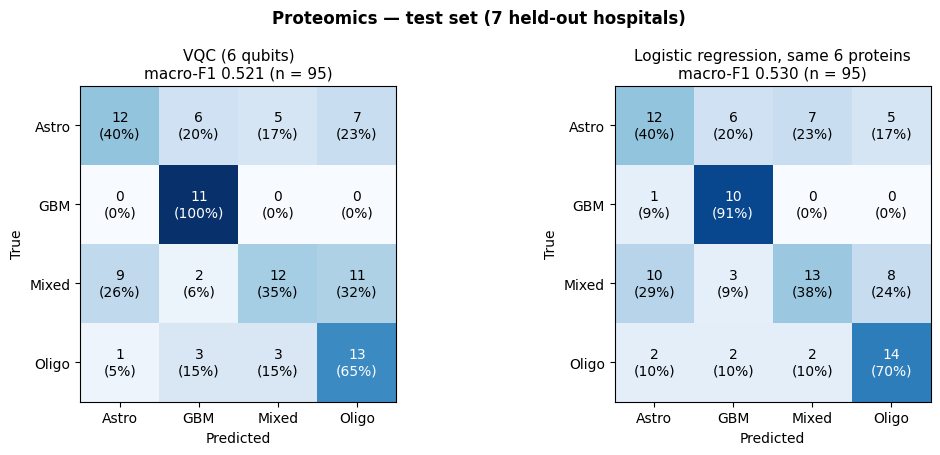

In [11]:
# ============================================================
# 8. CONFUSION MATRICES ON THE 7 HELD-OUT SITES (VQC vs matched LR)
# ============================================================
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score

SHORT = ["Astro", "GBM", "Mixed", "Oligo"]
y_true = cohort.loc[te_ids, "subtype"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (model, title) in zip(axes, [("VQC", "VQC (6 qubits)"), ("LRm", "Logistic regression, same 6 proteins")]):
    P = PROBS[(PROBS.model == model) & (PROBS.set == "test")].set_index("patient").loc[te_ids, CLASSES]
    y_pred = P.idxmax(axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    rec = cm / cm.sum(axis=1, keepdims=True).clip(min=1)               # row-normalised = recall per class
    ax.imshow(rec, cmap="Blues", vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cm[i, j]}\n({rec[i, j]:.0%})", ha="center", va="center", fontsize=10,
                    color="white" if rec[i, j] > 0.55 else "black")
    ax.set_xticks(range(K), SHORT); ax.set_yticks(range(K), SHORT)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    mf1 = f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0)
    ax.set_title(f"{title}\nmacro-F1 {mf1:.3f} (n = {len(y_true)})", fontsize=11)
fig.suptitle("Proteomics — test set (7 held-out hospitals)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "proteomics_confusion_matrix.png"), dpi=200, bbox_inches="tight")
plt.show()

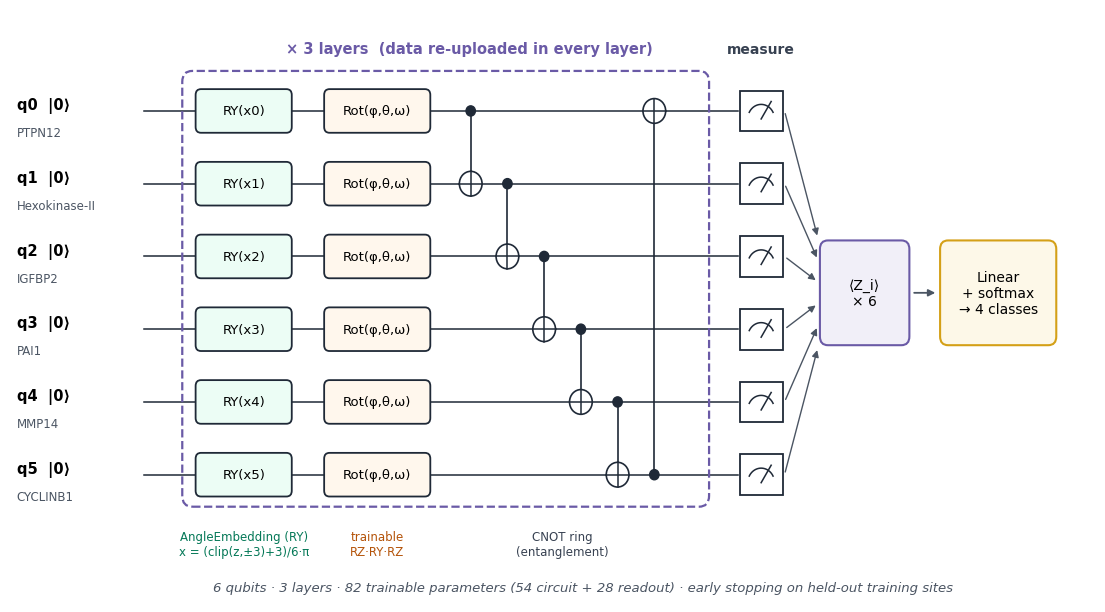

In [12]:
# ============================================================
# 9. VQC CIRCUIT DIAGRAM (final model: 6 qubits, 3 re-uploading layers of
#    AngleEmbedding(RY) + StronglyEntanglingLayers = Rot on every qubit + CNOT ring)
# ============================================================
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Circle

prots = [str(f) for f in QOUT[-1]["features"]]                      # proteins of the final model (qubit order)
n = len(prots)
ring = [(q, (q + 1) % n) for q in range(n)]
x_enc, x_rot, x_c0, dx = 0.9, 2.9, 4.3, 0.55
x_end = x_c0 + dx * (len(ring) - 1) + 0.6
x_meas = x_end + 1.0
fig, ax = plt.subplots(figsize=(14, 0.95 * n + 2.0))
ax.set_xlim(-2.6, x_meas + 5.0); ax.set_ylim(-1.75, n + 0.4); ax.axis("off")
Y = lambda q: n - 1 - q


def gate(x, y, text, fc, w=1.4):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - 0.28), w, 0.56, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec="#1f2937", lw=1.3, zorder=3))
    ax.text(x, y, text, ha="center", va="center", fontsize=9.5, zorder=4)


def meter(x, y):
    ax.add_patch(Rectangle((x - 0.32, y - 0.28), 0.64, 0.56, fc="white", ec="#1f2937", lw=1.3, zorder=3))
    th = np.linspace(np.pi * 0.15, np.pi * 0.85, 30)
    ax.plot(x + 0.2 * np.cos(th), y - 0.11 + 0.2 * np.sin(th), color="#1f2937", lw=1.1, zorder=4)
    ax.plot([x, x + 0.15], [y - 0.11, y + 0.13], color="#1f2937", lw=1.1, zorder=4)


for q in range(n):
    y = Y(q)
    ax.text(-2.5, y + 0.08, f"q{q}  |0⟩", ha="left", va="center", fontsize=10.5, fontweight="bold")
    ax.text(-2.5, y - 0.3, prots[q], ha="left", va="center", fontsize=8.5, color="#4b5563")
    ax.plot([-0.6, x_meas - 0.35], [y, y], color="#1f2937", lw=1.1, zorder=1)
    gate(x_enc, y, f"RY(x{q})", "#ecfdf5")
    gate(x_rot, y, f"Rot(φ,θ,ω)", "#fff7ed", w=1.55)
    meter(x_meas, y)

for k, (c, t) in enumerate(ring):                                   # CNOT ring: control dot, target ⊕
    x = x_c0 + dx * k
    ax.plot([x, x], [Y(c), Y(t)], color="#1f2937", lw=1.2, zorder=2)
    ax.add_patch(Circle((x, Y(c)), 0.07, color="#1f2937", zorder=4))
    ax.add_patch(Circle((x, Y(t)), 0.17, fc="white", ec="#1f2937", lw=1.2, zorder=4))
    ax.plot([x - 0.17, x + 0.17], [Y(t), Y(t)], color="#1f2937", lw=1.1, zorder=5)
    ax.plot([x, x], [Y(t) - 0.17, Y(t) + 0.17], color="#1f2937", lw=1.1, zorder=5)

# one layer, repeated 3 times
ax.add_patch(FancyBboxPatch((x_enc - 0.9, -0.42), x_end - x_enc + 1.1, n - 0.05,
                            boxstyle="round,pad=0.02,rounding_size=0.15", fc="none", ec="#6a5aa6", lw=1.6, ls="--"))
ax.text((x_enc + x_end) / 2, n - 0.2, "× 3 layers  (data re-uploaded in every layer)", ha="center",
        fontsize=10.5, color="#6a5aa6", fontweight="bold")
ax.text(x_enc, -0.95, "AngleEmbedding (RY)\nx = (clip(z,±3)+3)/6·π", ha="center", va="center", fontsize=8.5, color="#047857")
ax.text(x_rot, -0.95, "trainable\nRZ·RY·RZ", ha="center", va="center", fontsize=8.5, color="#b45309")
ax.text(x_c0 + dx * (len(ring) - 1) / 2, -0.95, "CNOT ring\n(entanglement)", ha="center", va="center", fontsize=8.5,
        color="#374151")
ax.text(x_meas, n - 0.2, "measure", ha="center", fontsize=10, color="#374151", fontweight="bold")

xb = x_meas + 0.9
ax.add_patch(FancyBboxPatch((xb, (n - 1) / 2 - 0.7), 1.3, 1.4, boxstyle="round,pad=0.02,rounding_size=0.12",
                            fc="#f1eff8", ec="#6a5aa6", lw=1.5))
ax.text(xb + 0.65, (n - 1) / 2, f"⟨Z_i⟩\n× {n}", ha="center", va="center", fontsize=10)
ax.add_patch(FancyBboxPatch((xb + 1.8, (n - 1) / 2 - 0.7), 1.7, 1.4, boxstyle="round,pad=0.02,rounding_size=0.12",
                            fc="#fdf8e8", ec="#d4a017", lw=1.5))
ax.text(xb + 2.65, (n - 1) / 2, "Linear\n+ softmax\n→ 4 classes", ha="center", va="center", fontsize=10)
for q in range(n):
    ax.annotate("", xy=(xb - 0.05, (n - 1) / 2 + (Y(q) - (n - 1) / 2) * 0.3), xytext=(x_meas + 0.35, Y(q)),
                arrowprops=dict(arrowstyle="-|>", color="#4b5563", lw=1.0))
ax.annotate("", xy=(xb + 1.75, (n - 1) / 2), xytext=(xb + 1.35, (n - 1) / 2),
            arrowprops=dict(arrowstyle="-|>", color="#4b5563", lw=1.3))
nq = 3 * 3 * n
ax.text((x_enc + xb + 3.5) / 2 - 1, -1.6, f"{n} qubits · 3 layers · {QOUT[-1]['n_params']} trainable parameters "
        f"({nq} circuit + {QOUT[-1]['n_params'] - nq} readout) · early stopping on held-out training sites",
        ha="center", fontsize=9.5, color="#4b5563", style="italic")
plt.savefig(os.path.join(OUTPUT_DIR, "proteomics_vqc_circuit.png"), dpi=200, bbox_inches="tight")
plt.show()

In [13]:
# %% ---------------- CELL C0 — settings, helpers and model capture ----------------
import os, time, json, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
warnings.filterwarnings("ignore")

QUICK = False                   # True = fewer repeats / trajectories, for a first test run
RUN_FAKE_HARDWARE = True        # needs internet on (pip install qiskit qiskit-aer qiskit-ibm-runtime); circuits <= 7 qubits
LC_FRACS = [0.25, 0.5, 0.75, 1.0]
LC_REPEATS = 2 if QUICK else 3
SEED_REPEATS = 2 if QUICK else 4
NOISE_P = [0, 3e-4, 1e-3, 3e-3, 1e-2]          # depolarising prob. per 1-qubit gate; 2-qubit gates use 10 x p
N_TRAJ = 30 if QUICK else 100
SHOT_LEVELS = [256, 1024, 4096]
N_BOOT_C = 2000
C_DIR = os.path.join(OUTPUT_DIR, f"partC_{MODALITY}"); os.makedirs(C_DIR, exist_ok=True)
SITE = cohort["site"]

y_te = y_idx(te_ids)
mf1 = lambda y, p: f1_score(y, p, labels=list(range(K)), average="macro", zero_division=0)
_p = lambda model, st, idx: PROBS[(PROBS.model == model) & (PROBS.set == st)].set_index("patient").loc[idx, CLASSES].values
VQC_TEST, LRM_TEST, LR_TEST = _p("VQC", "test", te_ids), _p("LRm", "test", te_ids), _p("LR", "test", te_ids)
VQC_OOF = _p("VQC", "oof", ids)
FOLD_OF = FOLD.loc[ids].values


def paired(y, pa, pb, b=N_BOOT_C, seed=42):
    rng = np.random.default_rng(seed); d = []
    for _ in range(b):
        i = rng.integers(0, len(y), len(y)); d.append(mf1(y[i], pa[i]) - mf1(y[i], pb[i]))
    d = np.array(d); p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
    return float(d.mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5)), max(p, 1.0 / b)


def ci(y, p, b=N_BOOT_C, seed=42):
    rng = np.random.default_rng(seed)
    v = [mf1(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(b))]
    return float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))


# ---- capture: record the trained VQC objects and the exact VQC input features while run_quantum runs ----
CAP = {}


class Capture:
    """Temporarily wraps HybridVQC / QuantumClassifier / matched_lr so a run_quantum call leaves behind the trained
    model objects, their test inputs, and the feature matrices given to the matched logistic regression."""
    def __enter__(self):
        CAP.clear(); CAP.update(models=[], pred=[], lr=[]); g = globals(); self.saved = {}
        for cname in ["HybridVQC", "QuantumClassifier"]:
            if cname in g:
                C = g[cname]; self.saved[cname] = (C.fit, C.predict_proba)
                f0, p0 = C.fit, C.predict_proba
                def fit(m, *a, _f0=f0, **k):
                    r = _f0(m, *a, **k); CAP["models"].append(m); return r
                def pp(m, A, _p0=p0):
                    CAP["pred"].append((m, np.array(A, dtype=float))); return _p0(m, A)
                C.fit, C.predict_proba = fit, pp
        if "matched_lr" in g:
            self.saved["matched_lr"] = g["matched_lr"]; orig = g["matched_lr"]
            def mlr(F_fit, y_fit, F_pred, _o=orig):
                CAP["lr"].append((np.array(F_fit, float), np.array(y_fit), np.array(F_pred, float)))
                return _o(F_fit, y_fit, F_pred)
            g["matched_lr"] = mlr
        return self

    def __exit__(self, *a):
        g = globals()
        for cname in ["HybridVQC", "QuantumClassifier"]:
            if cname in self.saved:
                g[cname].fit, g[cname].predict_proba = self.saved[cname]
        if "matched_lr" in self.saved:
            g["matched_lr"] = self.saved["matched_lr"]


class NoEntangle:
    """Removes every entangling gate (CNOT, CZ, IsingZZ / RZZ) from this modality's circuit while active."""
    def __enter__(self):
        g = globals(); self.saved = {}
        if "QSim" in g:
            Q = g["QSim"]; self.saved["QSim"] = Q.__init__; i0 = Q.__init__
            def init(s, n, ops, observables, _i0=i0):
                _i0(s, n, [op for op in ops if op[0] not in ("cnot", "cz", "zz_x")], observables)
            Q.__init__ = init
        if "FastVQC" in g:
            F = g["FastVQC"]; self.saved["FastVQC"] = F.__init__; i1 = F.__init__
            def initf(s, *a, _i1=i1, **k):
                _i1(s, *a, **k); s.cz = np.ones_like(s.cz); s.pairs = []
            F.__init__ = initf
        if "QuantumClassifier" in g:
            C = g["QuantumClassifier"]; self.saved["QC"] = C._build; b0 = C._build
            def build(s, n, _b0=b0):
                ops, p = _b0(s, n); return [op for op in ops if op.kind not in ("cnot", "rzz")], p
            C._build = build
        return self

    def __exit__(self, *a):
        g = globals()
        if "QSim" in self.saved: g["QSim"].__init__ = self.saved["QSim"]
        if "FastVQC" in self.saved: g["FastVQC"].__init__ = self.saved["FastVQC"]
        if "QC" in self.saved: g["QuantumClassifier"]._build = self.saved["QC"]


HAS_ENTANGLERS = MODALITY != "methylation"
print(f"Part C for {MODALITY}: train {len(ids)} | test {len(te_ids)} | output {C_DIR}")

Part C for proteomics: train 223 | test 95 | output /kaggle/working/partC_proteomics


In [14]:
# %% ---------------- CELL C1 — re-run the VQC once with capture (features, trained models, timing) ----------------
FEATS, TIMES, FINAL_CAP = {}, {}, None
for tag, fit, pred in jobs:
    t0 = time.time()
    with Capture():
        out = run_quantum(fit, pred, str(tag))
    TIMES[str(tag)] = time.time() - t0
    if CAP["lr"]:
        F_fit, _, F_pred = CAP["lr"][-1]
    else:   # proteomics: same proteins, median imputation fitted on the training patients of this fit
        feats = out["features"]; imp = SimpleImputer(strategy="median", keep_empty_features=True).fit(XM.loc[fit, feats])
        F_fit, F_pred = imp.transform(XM.loc[fit, feats]), imp.transform(XM.loc[pred, feats])
    FEATS[str(tag)] = dict(F_fit=F_fit, y_fit=y_idx(fit), F_pred=F_pred, fit=fit, pred=pred, vqc=out["VQC"].values,
                           n_params=out["n_params"], features=list(map(str, out["features"])))
    if tag == "final":
        FINAL_CAP = {k: list(v) for k, v in CAP.items()}
    print(f"  {str(tag):5s}: VQC fit + predict {TIMES[str(tag)]:.1f}s")
repro = float(np.abs(FEATS["final"]["vqc"] - VQC_TEST).max())
print(f"Re-run reproduces the saved test probabilities: max difference {repro:.2e}" +
      ("" if repro < 1e-6 else "  (small differences come from parallel vs sequential BLAS; results below use the re-run)"))
N_FEAT = FEATS["final"]["F_fit"].shape[1]; VQC_PARAMS = FEATS["final"]["n_params"]
VQC_OOF_RERUN = np.zeros((len(ids), K))
for tag, fit, pred in jobs:
    if tag != "final":
        VQC_OOF_RERUN[np.isin(ids, pred)] = FEATS[str(tag)]["vqc"]
VQC_TEST_RERUN = FEATS["final"]["vqc"]

  0    : VQC fit + predict 1.5s
  1    : VQC fit + predict 0.6s
  2    : VQC fit + predict 1.8s
  3    : VQC fit + predict 0.7s
  4    : VQC fit + predict 1.8s
  final: VQC fit + predict 1.6s
Re-run reproduces the saved test probabilities: max difference 0.00e+00


In [15]:
# %% ---------------- CELL C2 — classical baselines on exactly the VQC's features ----------------
# LR (same features) | MLP with the same number of trainable parameters as the VQC | LR on degree-2 polynomial
# features (squares + pairwise products: tests whether the pairwise (ZZ-type) interactions are classically easy) |
# RBF-kernel SVM | quantum-kernel SVM (ZZ feature map, Havlicek et al. 2019) — all tuned by 4-fold site-grouped CV
# inside each training set.
H_MLP = max(1, int(round((VQC_PARAMS - K) / (N_FEAT + 1 + K))))
MLP_PARAMS = N_FEAT * H_MLP + H_MLP + H_MLP * K + K


def inner_cv(fit):
    return StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE).split(np.zeros(len(fit)), y_idx(fit), SITE.loc[fit].values)


def balanced_rows(y, seed):
    rng = np.random.default_rng(seed); m = np.bincount(y, minlength=K).max()
    return np.concatenate([rng.choice(np.where(y == c)[0], m, replace=True) for c in range(K) if (y == c).any()])


def fit_mlp(F, y, Fp, seeds=(0, 1, 2)):
    sc = StandardScaler().fit(F); P = []
    for s in seeds:
        r = balanced_rows(y, s)
        m = MLPClassifier(hidden_layer_sizes=(H_MLP,), activation="tanh", alpha=1e-3, max_iter=3000, random_state=s)
        m.fit(sc.transform(F)[r], y[r]); q = np.zeros((len(Fp), K)); q[:, m.classes_] = m.predict_proba(sc.transform(Fp)); P.append(q)
    return np.mean(P, 0)


def fit_grid(pipe, grid, F, y, Fp, fit):
    gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=list(inner_cv(fit)), n_jobs=-1).fit(F, y)
    return gs.predict(Fp), gs.best_params_


def zz_states(A):
    # ZZ feature map, 2 repetitions, linear entanglement: |psi(x)> = U(x) H U(x) H |0>, U(x) = exp(-i[sum x_i Z_i +
    # sum (pi - x_i)(pi - x_j) Z_i Z_j]) on neighbouring pairs
    B, n = A.shape; idx = np.arange(2 ** n)
    Z = np.array([1 - 2 * ((idx >> (n - 1 - q)) & 1) for q in range(n)], float)
    phase = A @ Z + sum(((np.pi - A[:, i]) * (np.pi - A[:, i + 1]))[:, None] * (Z[i] * Z[i + 1])[None, :] for i in range(n - 1))
    def hadamard_all(psi):
        v = psi.reshape((B,) + (2,) * n)
        for q in range(n):
            a0 = np.take(v, 0, axis=q + 1); a1 = np.take(v, 1, axis=q + 1)
            v = np.stack([(a0 + a1) / np.sqrt(2), (a0 - a1) / np.sqrt(2)], axis=q + 1)
        return v.reshape(B, -1)
    psi = np.full((B, 2 ** n), 2 ** (-n / 2), complex)
    for rep in range(2):
        psi = psi * np.exp(-1j * phase)
        if rep == 0:
            psi = hadamard_all(psi)
    return psi


def fit_qkernel(F, y, Fp, fit):
    sc = StandardScaler().fit(F)
    ang = lambda X: (np.clip(sc.transform(X), -3, 3) + 3) / 6 * np.pi
    best = (-1, None)
    for bw in [0.25, 0.5, 1.0]:               # kernel bandwidth (angle scaling); tuned like gamma of the RBF kernel
        S = zz_states(bw * ang(F)); Kt = np.abs(S @ S.conj().T) ** 2
        gs = GridSearchCV(SVC(kernel="precomputed", class_weight="balanced"), {"C": [0.1, 1, 10]}, scoring="f1_macro",
                          cv=list(inner_cv(fit))).fit(Kt, y)
        if gs.best_score_ > best[0]:
            Sp = zz_states(bw * ang(Fp)); best = (gs.best_score_, (gs.predict(np.abs(Sp @ S.conj().T) ** 2), {"bandwidth": bw, **gs.best_params_}))
    return best[1]


lr_pipe = lambda: Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=5000, class_weight="balanced"))])
BASELINES = {
    "LR (same features)": lambda F, y, Fp, fit: (lr_pipe().fit(F, y).predict(Fp), {}),
    f"MLP ({H_MLP} hidden, {MLP_PARAMS} params)": lambda F, y, Fp, fit: (fit_mlp(F, y, Fp).argmax(1), {"hidden": H_MLP}),
    "LR, degree-2 polynomial features": lambda F, y, Fp, fit: fit_grid(
        Pipeline([("sc", StandardScaler()), ("poly", PolynomialFeatures(2, include_bias=False)), ("sc2", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=5000, class_weight="balanced"))]), {"clf__C": [0.01, 0.1, 1.0]}, F, y, Fp, fit),
    "RBF-kernel SVM": lambda F, y, Fp, fit: fit_grid(
        Pipeline([("sc", StandardScaler()), ("svm", SVC(kernel="rbf", class_weight="balanced"))]),
        {"svm__C": [0.1, 1, 10], "svm__gamma": ["scale", 0.03, 0.3]}, F, y, Fp, fit),
    "Quantum-kernel SVM (ZZ map)": fit_qkernel,
}
rows, BASE_PRED, BASE_TIME = [], {}, {}
for name, fn in BASELINES.items():
    t0 = time.time(); oof = np.zeros(len(ids), int); best = None
    for tag, fit, pred in jobs:
        f = FEATS[str(tag)]; pr, bp = fn(f["F_fit"], f["y_fit"], f["F_pred"], fit)
        if tag == "final":
            te, best = pr, bp
        else:
            oof[np.isin(ids, pred)] = pr
    BASE_PRED[name] = te; BASE_TIME[name] = time.time() - t0
    lo, hi = ci(y_te, te); d, dlo, dhi, pv = paired(y_te, VQC_TEST_RERUN.argmax(1), te)
    rows.append({"model": name, "cv_macro_f1": mf1(y_idx(ids), oof), "test_macro_f1": mf1(y_te, te), "ci_low": lo, "ci_high": hi,
                 "vqc_minus_model": d, "diff_ci_low": dlo, "diff_ci_high": dhi, "p": pv, "final_settings": str(best),
                 "time_6_fits_s": BASE_TIME[name]})
    print(f"  {name:38s} test {mf1(y_te, te):.3f}  ({BASE_TIME[name]:.0f}s)")
lo, hi = ci(y_te, VQC_TEST_RERUN.argmax(1))
rows.insert(0, {"model": f"VQC ({N_FEAT} qubits, {VQC_PARAMS} params)", "cv_macro_f1": mf1(y_idx(ids), VQC_OOF_RERUN.argmax(1)),
                "test_macro_f1": mf1(y_te, VQC_TEST_RERUN.argmax(1)), "ci_low": lo, "ci_high": hi, "time_6_fits_s": sum(TIMES.values())})
C2 = pd.DataFrame(rows); C2.to_csv(os.path.join(C_DIR, "C2_classical_baselines.csv"), index=False)
print("\nPositive 'vqc_minus_model' = VQC better (paired bootstrap on the test patients).")
display(C2.drop(columns=["final_settings"]).round(3))

  LR (same features)                     test 0.524  (0s)
  MLP (7 hidden, 81 params)              test 0.528  (21s)
  LR, degree-2 polynomial features       test 0.524  (1s)
  RBF-kernel SVM                         test 0.548  (1s)
  Quantum-kernel SVM (ZZ map)            test 0.445  (2s)

Positive 'vqc_minus_model' = VQC better (paired bootstrap on the test patients).


,model,cv_macro_f1,test_macro_f1,ci_low,ci_high,time_6_fits_s,vqc_minus_model,diff_ci_low,diff_ci_high,p
0,"VQC (6 qubits, 82 params)",0.528,0.521,0.414,0.617,8.019,NaN,NaN,NaN,NaN
1,LR (same features),0.511,0.524,0.416,0.619,0.063,-0.002,-0.090,0.084,0.952
2,"MLP (7 hidden, 81 params)",0.530,0.528,0.420,0.622,21.218,-0.006,-0.089,0.079,0.889
3,"LR, degree-2 polynomial features",0.577,0.524,0.415,0.617,0.889,-0.003,-0.097,0.093,0.952
4,RBF-kernel SVM,0.477,0.548,0.428,0.642,1.018,-0.025,-0.114,0.060,0.565
5,Quantum-kernel SVM (ZZ map),0.471,0.445,0.333,0.540,2.137,0.077,-0.033,0.197,0.183


  0.25 rep 0: n=56 VQC 0.211 | LR same 0.317 | LR tuned 0.468
  0.25 rep 1: n=56 VQC 0.368 | LR same 0.386 | LR tuned 0.554
  0.25 rep 2: n=56 VQC 0.311 | LR same 0.306 | LR tuned 0.613
  0.50 rep 0: n=111 VQC 0.395 | LR same 0.484 | LR tuned 0.583
  0.50 rep 1: n=111 VQC 0.244 | LR same 0.364 | LR tuned 0.560
  0.50 rep 2: n=111 VQC 0.370 | LR same 0.421 | LR tuned 0.518
  0.75 rep 0: n=167 VQC 0.476 | LR same 0.520 | LR tuned 0.589
  0.75 rep 1: n=167 VQC 0.400 | LR same 0.453 | LR tuned 0.533
  0.75 rep 2: n=167 VQC 0.304 | LR same 0.366 | LR tuned 0.535
  1.00 rep 0: n=223 VQC 0.521 | LR same 0.530 | LR tuned 0.584


n_train         VQC        LR (same features)        LR (tuned)       
            mean  std   mean    std               mean    std       mean    std
fraction                                                                       
0.25        56.0  0.0  0.296  0.080              0.336  0.043      0.545  0.073
0.50       111.0  0.0  0.336  0.081              0.423  0.060      0.554  0.033
0.75       167.0  0.0  0.393  0.086              0.446  0.077      0.553  0.032
1.00       223.0  NaN  0.521    NaN              0.530    NaN      0.584    NaN

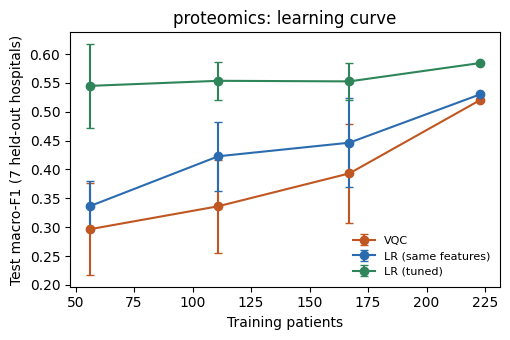

In [16]:
# %% ---------------- CELL C3 — learning curves: test macro-F1 vs size of the training set ----------------
def stratified_subset(pool, frac, seed):
    rng = np.random.default_rng(seed); y = y_idx(pool); keep = []
    for c in range(K):
        idx = np.where(y == c)[0]
        if len(idx):
            keep.extend(rng.choice(idx, max(2, int(round(frac * len(idx)))), replace=False))
    return pool[np.sort(keep)]


rows = []
for frac in LC_FRACS:
    for rep in range(1 if frac == 1.0 else LC_REPEATS):
        sub = ids if frac == 1.0 else stratified_subset(ids, frac, 100 + rep)
        t0 = time.time()
        out = run_quantum(sub, te_ids, "final")
        gs = tune_base(sub, RANDOM_STATE); plr = proba_df(gs, XM.loc[te_ids]).values
        rows.append({"fraction": frac, "repeat": rep, "n_train": len(sub),
                     "VQC": mf1(y_te, out["VQC"].values.argmax(1)), "LR (same features)": mf1(y_te, out["LRm"].values.argmax(1)),
                     "LR (tuned)": mf1(y_te, plr.argmax(1)), "seconds": time.time() - t0})
        print(f"  {frac:.2f} rep {rep}: n={len(sub)} VQC {rows[-1]['VQC']:.3f} | LR same {rows[-1]['LR (same features)']:.3f}"
              f" | LR tuned {rows[-1]['LR (tuned)']:.3f}")
C3 = pd.DataFrame(rows); C3.to_csv(os.path.join(C_DIR, "C3_learning_curve.csv"), index=False)
agg = C3.groupby("fraction")[["n_train", "VQC", "LR (same features)", "LR (tuned)"]].agg(["mean", "std"])
display(agg.round(3))
fig, ax = plt.subplots(figsize=(5.2, 3.5))
for col, c_ in [("VQC", "#c05621"), ("LR (same features)", "#2b6cb0"), ("LR (tuned)", "#2f855a")]:
    m, s = C3.groupby("fraction")[col].mean(), C3.groupby("fraction")[col].std().fillna(0)
    n = C3.groupby("fraction")["n_train"].mean()
    ax.errorbar(n, m, yerr=s, fmt="o-", color=c_, capsize=3, label=col)
ax.set_xlabel("Training patients"); ax.set_ylabel("Test macro-F1 (7 held-out hospitals)"); ax.set_title(f"{MODALITY}: learning curve")
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(os.path.join(C_DIR, "figC3_learning_curve.png"), dpi=200); plt.show()

In [17]:
# %% ---------------- CELL C4 — entanglement ablation and seed-to-seed variation ----------------
rows = []
if HAS_ENTANGLERS:
    oof = np.zeros((len(ids), K)); t0 = time.time()
    with NoEntangle():
        for tag, fit, pred in jobs:
            out = run_quantum(fit, pred, str(tag))
            if tag == "final":
                te_ne = out["VQC"].values
            else:
                oof[np.isin(ids, pred)] = out["VQC"].values
    d, dlo, dhi, pv = paired(y_te, VQC_TEST_RERUN.argmax(1), te_ne.argmax(1))
    rows.append({"variant": "with entangling gates (as in the paper)", "cv_macro_f1": mf1(y_idx(ids), VQC_OOF_RERUN.argmax(1)),
                 "test_macro_f1": mf1(y_te, VQC_TEST_RERUN.argmax(1))})
    rows.append({"variant": "without entangling gates", "cv_macro_f1": mf1(y_idx(ids), oof.argmax(1)), "test_macro_f1": mf1(y_te, te_ne.argmax(1)),
                 "with_minus_without": d, "diff_ci_low": dlo, "diff_ci_high": dhi, "p": pv})
    print(f"No-entanglement run: {time.time() - t0:.0f}s")
else:
    rows.append({"variant": "methylation circuit has no entangling gates: ablation not applicable",
                 "test_macro_f1": mf1(y_te, VQC_TEST_RERUN.argmax(1))})
C4a = pd.DataFrame(rows); C4a.to_csv(os.path.join(C_DIR, "C4a_entanglement_ablation.csv"), index=False); display(C4a.round(4))

SEED_KNOBS = {"proteomics": ["RANDOM_STATE"], "gene_expression": ["RANDOM_STATE"], "methylation": ["ME_SEEDS"],
              "mirna": ["MI_SEEDS"], "snv": ["SNV_SEEDS"], "cnv": ["CFG_VQC"]}[MODALITY]
saved = {k: copy.deepcopy(globals()[k]) for k in SEED_KNOBS}
f1s = [mf1(y_te, VQC_TEST_RERUN.argmax(1))]
try:
    for r in range(1, SEED_REPEATS + 1):
        for k in SEED_KNOBS:
            v = saved[k]
            if k == "RANDOM_STATE": globals()[k] = v + 1000 * r
            elif k == "CFG_VQC": globals()[k] = {**v, "seed": v.get("seed", 0) + 1000 * r}
            else: globals()[k] = type(v)(s + 1000 * r for s in v)
        f1s.append(mf1(y_te, run_quantum(ids, te_ids, "final")["VQC"].values.argmax(1)))
        print(f"  seed set {r}: test macro-F1 {f1s[-1]:.3f}")
finally:
    for k in SEED_KNOBS:
        globals()[k] = saved[k]
C4b = pd.DataFrame({"seed_set": range(len(f1s)), "test_macro_f1": f1s})
C4b.to_csv(os.path.join(C_DIR, "C4b_seed_variation.csv"), index=False)
print(f"Seed-to-seed: test macro-F1 {np.mean(f1s):.3f} ± {np.std(f1s, ddof=1):.3f} (SD over {len(f1s)} seed sets; "
      f"set 0 = the paper's seeds; '{', '.join(SEED_KNOBS)}' changed)")

No-entanglement run: 16s


,variant,cv_macro_f1,test_macro_f1,with_minus_without,diff_ci_low,diff_ci_high,p
0,with entangling gates (as in the paper),0.5278,0.5206,NaN,NaN,NaN,NaN
1,without entangling gates,0.4390,0.5158,0.0057,-0.0968,0.1042,0.914


  seed set 1: test macro-F1 0.449
  seed set 2: test macro-F1 0.421
  seed set 3: test macro-F1 0.449
  seed set 4: test macro-F1 0.557
Seed-to-seed: test macro-F1 0.479 ± 0.057 (SD over 5 seed sets; set 0 = the paper's seeds; 'RANDOM_STATE' changed)


In [18]:
# %% ---------------- CELL C5 — the trained final VQC as a gate list (for noise, shots and hardware) ----------------
# Every trained model of the final fit (all seeds of an ensemble) becomes {gates with per-patient angles, readout
# terms, linear head}. A noise-free re-simulation must reproduce the VQC's test probabilities exactly.
def _obs_from_O(O, n, zsign_rows):
    terms = [(q,) for q in range(n)] + [(i, j) for i in range(n) for j in range(i + 1, n)]
    out = []
    for row in O:
        out.append(next(t for t in terms if np.allclose(np.prod([zsign_rows[q] for q in t], axis=0), row)))
    return out


def members_from_capture():
    mem = []
    if MODALITY == "snv":       # train_snv keeps no model object: retrain the same 5 seeds and keep the parameters
        F_tr, y_tr, F_te = CAP_FINAL_LR
        for s in SNV_SEEDS:
            eng = FastVQC(F_tr.shape[1]); rng = np.random.default_rng(s)
            Xu, inv = unique_patterns(F_tr); Xa = Xu * np.pi; N = len(y_tr)
            sw = (N / (K * np.bincount(y_tr, minlength=K)))[y_tr][:, None]; Yo = np.eye(K)[y_tr]
            q = rng.normal(0, INIT_STD, eng.n_params); W = rng.normal(0, INIT_STD, (K, eng.n)); b = np.zeros(K)
            P = [q, W, b]; m1 = [np.zeros_like(p) for p in P]; m2 = [np.zeros_like(p) for p in P]
            for ep in range(1, EPOCHS + 1):
                psi = eng.state(Xa, q); Zu = eng.expz(psi); Zz = Zu[inv]; pr = _softmax(Zz @ W.T + b)
                dl = sw * (pr - Yo) / N; dZu = np.zeros_like(Zu); np.add.at(dZu, inv, dl @ W)
                for i, g in enumerate([eng.grad(Xa, q, psi, dZu), dl.T @ Zz, dl.sum(0)]):
                    m1[i] = 0.9 * m1[i] + 0.1 * g; m2[i] = 0.999 * m2[i] + 0.001 * g * g
                    P[i] -= LEARNING_RATE * (m1[i] / (1 - 0.9 ** ep)) / (np.sqrt(m2[i] / (1 - 0.999 ** ep)) + 1e-8)
            n = eng.n; B = len(F_te); gates = []
            for l in range(N_LAYERS):
                for qb in range(n):
                    gates.append(("ry", (qb,), np.pi * F_te[:, qb])); gates.append(("ry", (qb,), np.full(B, q[2 * (l * n + qb)])))
                for qb in range(n):
                    gates.append(("rz", (qb,), np.full(B, q[2 * (l * n + qb) + 1])))
                gates += [("cz", pr_, None) for pr_ in eng.pairs]
            mem.append(dict(n=n, gates=gates, obs=[(qb,) for qb in range(n)], W=W.T, b=b))
        return mem
    for m, A in FINAL_CAP["pred"]:
        if type(m).__name__ == "HybridVQC":
            sim = m.sim; th, W, b = m.P_; B = len(A); gates = []
            for op in sim.ops:
                k = op[0]
                if k in ("ry_x", "rx_x"): gates.append((k[:2], (op[1],), A[:, op[2]]))
                elif k == "zz_x": gates.append(("rzz", (op[1], op[2]), A[:, op[3]]))
                elif k in ("ry", "rz"): gates.append((k, (op[1],), np.full(B, th[op[2]])))
                else: gates.append((k, (op[1], op[2]), None))
            mem.append(dict(n=sim.n, gates=gates, obs=_obs_from_O(sim.O, sim.n, sim.zsign), W=W.T, b=b))
        else:   # CNV QuantumClassifier
            D = m._data(m._scale(A)); gates = []
            for op in m.ops_:
                if op.kind in ("ry", "rz", "rzz", "rx"): gates.append((op.kind, op.wires, Simulator.angles(op, m.params_, D)))
                else: gates.append((op.kind, op.wires, None))
            mem.append(dict(n=m.sim_.n, gates=gates, obs=list(m.ro_terms_), W=m.params_[m.ro_s_], b=m.params_[m.ro_b_]))
    return mem


def _zs(n, t):
    idx = np.arange(2 ** n); s = np.ones(2 ** n)
    for q in t:
        s = s * (1 - 2 * ((idx >> (n - 1 - q)) & 1))
    return s


def _apply(psi, n, kind, w, a):
    B = psi.shape[0]
    if kind in ("ry", "rx"):
        v = psi.reshape(B, 2 ** w[0], 2, -1); c, s = np.cos(a / 2)[:, None, None], np.sin(a / 2)[:, None, None]
        a0, a1 = v[:, :, 0, :], v[:, :, 1, :]; o = np.empty_like(v)
        if kind == "ry": o[:, :, 0, :], o[:, :, 1, :] = c * a0 - s * a1, s * a0 + c * a1
        else: o[:, :, 0, :], o[:, :, 1, :] = c * a0 - 1j * s * a1, -1j * s * a0 + c * a1
        return o.reshape(B, -1)
    if kind == "rz": return psi * np.exp(-0.5j * a[:, None] * _zs(n, w)[None, :])
    if kind == "rzz": return psi * np.exp(-0.5j * a[:, None] * _zs(n, w)[None, :])
    if kind == "cz": return psi * np.where((_zs(n, (w[0],)) < 0) & (_zs(n, (w[1],)) < 0), -1.0, 1.0)[None, :]
    if kind == "cnot":
        v = psi.reshape((B,) + (2,) * n).copy(); sl = [slice(None)] * (n + 1); sl[w[0] + 1] = 1
        sub = v[tuple(sl)]; ax = w[1] + 1 if w[1] < w[0] else w[1]; v[tuple(sl)] = np.flip(sub, axis=ax); return v.reshape(B, -1)
    raise ValueError(kind)


def simulate(mem, rows, p=0.0, n_traj=1, rng=None):
    # returns readout values (len(rows), n_obs); with p > 0 a random Pauli (X, Y, Z) hits each qubit of a gate with
    # probability p (1-qubit gates) or 10 p (2-qubit gates) — quantum trajectories of the depolarising channel
    n = mem["n"]; R = np.repeat(rows, n_traj); B = len(R)
    psi = np.zeros((B, 2 ** n), complex); psi[:, 0] = 1
    for kind, w, a in mem["gates"]:
        psi = _apply(psi, n, kind, w, None if a is None else a[R])
        pe = p if len(w) == 1 else 10 * p
        if pe > 0:
            for q in w:
                hit = rng.random(B) < pe
                if hit.any():
                    which = rng.integers(0, 3, hit.sum()); sub = psi[hit].reshape(hit.sum(), 2 ** q, 2, -1); o = sub.copy()
                    x_, y_, z_ = which == 0, which == 1, which == 2
                    o[x_, :, 0], o[x_, :, 1] = sub[x_, :, 1], sub[x_, :, 0]
                    o[y_, :, 0], o[y_, :, 1] = -1j * sub[y_, :, 1], 1j * sub[y_, :, 0]
                    o[z_, :, 1] = -sub[z_, :, 1]
                    psi[hit] = o.reshape(hit.sum(), -1)
    S = np.stack([_zs(n, t) for t in mem["obs"]], 1)
    return ((np.abs(psi) ** 2) @ S).reshape(len(rows), n_traj, -1).mean(1), psi


def probs_from_z(mem, z):
    lg = z @ mem["W"] + mem["b"]; lg = lg - lg.max(1, keepdims=True); e = np.exp(lg); return e / e.sum(1, keepdims=True)


def ensemble_probs(MEM, zs):
    return np.mean([probs_from_z(m, z) for m, z in zip(MEM, zs)], 0)


CAP_FINAL_LR = (FEATS["final"]["F_fit"], FEATS["final"]["y_fit"], FEATS["final"]["F_pred"])
MEM = members_from_capture()
B_TE = len(te_ids); ALL = np.arange(B_TE)
chunk = lambda n, t: max(1, int(2 ** 22 / (2 ** n * t)))
z0 = [np.vstack([simulate(m, ALL[i:i + chunk(m["n"], 1)])[0] for i in range(0, B_TE, chunk(m["n"], 1))]) for m in MEM]
P0 = ensemble_probs(MEM, z0)
print(f"{len(MEM)} trained model(s), {MEM[0]['n']} qubits, {len(MEM[0]['gates'])} gates each. "
      f"Noise-free re-simulation vs the VQC's test probabilities: max difference {np.abs(P0 - VQC_TEST_RERUN).max():.2e}")

1 trained model(s), 6 qubits, 90 gates each. Noise-free re-simulation vs the VQC's test probabilities: max difference 5.00e-16


  p=0: test macro-F1 0.521, same prediction as noise-free for 100.0% of patients (1s)
  p=0.0003: test macro-F1 0.529, same prediction as noise-free for 96.8% of patients (1s)
  p=0.001: test macro-F1 0.497, same prediction as noise-free for 90.5% of patients (1s)
  p=0.003: test macro-F1 0.447, same prediction as noise-free for 75.8% of patients (1s)
  p=0.01: test macro-F1 0.166, same prediction as noise-free for 40.0% of patients (2s)


,setting,p_1q,shots,test_macro_f1,f1_sd,agreement_with_exact
0,"256 shots, no gate noise",0.0000,256.0,0.5126,0.0242,NaN
1,"1024 shots, no gate noise",0.0000,1024.0,0.5270,0.0144,NaN
2,"4096 shots, no gate noise",0.0000,4096.0,0.5103,0.0064,NaN
3,"depolarising p=0 (2-qubit 0), exact expectations",0.0000,inf,0.5206,NaN,1.0000
4,"depolarising p=0.0003 (2-qubit 0.003), exact e...",0.0003,inf,0.5292,NaN,0.9684
5,"depolarising p=0.001 (2-qubit 0.01), exact exp...",0.0010,inf,0.4973,NaN,0.9053
6,"depolarising p=0.003 (2-qubit 0.03), exact exp...",0.0030,inf,0.4471,NaN,0.7579
7,"depolarising p=0.01 (2-qubit 0.1), exact expec...",0.0100,inf,0.1663,NaN,0.4000


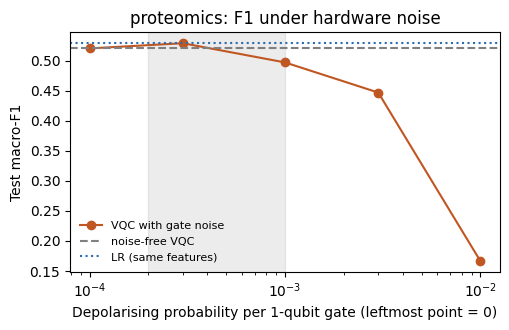

In [19]:
# %% ---------------- CELL C6 — F1 under finite shots and depolarising noise ----------------
rng = np.random.default_rng(42); rows = []
for shots in SHOT_LEVELS:
    f = []
    for r in range(3):
        zs = []
        for m in MEM:
            _, psi = simulate(m, ALL); pr = np.abs(psi) ** 2; pr = pr / pr.sum(1, keepdims=True)
            S = np.stack([_zs(m["n"], t) for t in m["obs"]], 1)
            zs.append(np.array([rng.multinomial(shots, row) @ S / shots for row in pr]))
        f.append(mf1(y_te, ensemble_probs(MEM, zs).argmax(1)))
    rows.append({"setting": f"{shots} shots, no gate noise", "p_1q": 0.0, "shots": shots, "test_macro_f1": np.mean(f),
                 "f1_sd": np.std(f), "agreement_with_exact": np.nan})
for p in NOISE_P:
    t0 = time.time(); zs = []
    for m in MEM:
        cs = chunk(m["n"], N_TRAJ)
        zs.append(np.vstack([simulate(m, ALL[i:i + cs], p, N_TRAJ, rng)[0] for i in range(0, B_TE, cs)]))
    Pn = ensemble_probs(MEM, zs)
    rows.append({"setting": f"depolarising p={p:g} (2-qubit {10 * p:g}), exact expectations", "p_1q": p, "shots": np.inf,
                 "test_macro_f1": mf1(y_te, Pn.argmax(1)), "f1_sd": np.nan,
                 "agreement_with_exact": float((Pn.argmax(1) == P0.argmax(1)).mean())})
    print(f"  p={p:g}: test macro-F1 {rows[-1]['test_macro_f1']:.3f}, same prediction as noise-free for "
          f"{100 * rows[-1]['agreement_with_exact']:.1f}% of patients ({time.time() - t0:.0f}s)")
C6 = pd.DataFrame(rows); C6.to_csv(os.path.join(C_DIR, "C6_noise_shots_f1.csv"), index=False); display(C6.round(4))
d = C6[C6.shots == np.inf]
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.semilogx([max(x, 1e-4) for x in d.p_1q], d.test_macro_f1, "o-", color="#c05621", label="VQC with gate noise")
ax.axhline(mf1(y_te, P0.argmax(1)), ls="--", color="grey", label="noise-free VQC")
ax.axhline(mf1(y_te, LRM_TEST.argmax(1)), ls=":", color="#2b6cb0", label="LR (same features)")
ax.axvspan(2e-4, 1e-3, color="grey", alpha=0.15)
ax.set_xlabel("Depolarising probability per 1-qubit gate (leftmost point = 0)"); ax.set_ylabel("Test macro-F1")
ax.set_title(f"{MODALITY}: F1 under hardware noise"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(C_DIR, "figC6_noise_f1.png"), dpi=200); plt.show()


In [20]:
# %% ---------------- CELL C7 — F1 on an emulated IBM device (Qiskit fake backend, device noise model) ----------------
C7 = None
n_q = MEM[0]["n"]
if RUN_FAKE_HARDWARE and n_q <= 7:
    try:
        try:
            import qiskit, qiskit_aer, qiskit_ibm_runtime  # noqa
        except ImportError:
            os.system("pip install -q qiskit qiskit-aer qiskit-ibm-runtime")
        from qiskit import QuantumCircuit, transpile
        from qiskit_aer import AerSimulator
        from qiskit_ibm_runtime import fake_provider as fp
        bk_name = "FakeManilaV2" if n_q <= 5 else "FakeLagosV2"
        backend = getattr(fp, bk_name)(); sim_hw = AerSimulator.from_backend(backend); SH = 4096; t0 = time.time()
        zs, n2q = [], []
        for m in MEM:
            circs = []
            for i in range(B_TE):
                qc = QuantumCircuit(m["n"])
                for kind, w, a in m["gates"]:
                    if kind == "ry": qc.ry(float(a[i]), w[0])
                    elif kind == "rx": qc.rx(float(a[i]), w[0])
                    elif kind == "rz": qc.rz(float(a[i]), w[0])
                    elif kind == "rzz": qc.rzz(float(a[i]), w[0], w[1])
                    elif kind == "cz": qc.cz(w[0], w[1])
                    elif kind == "cnot": qc.cx(w[0], w[1])
                qc.measure_all(); circs.append(qc)
            tc = transpile(circs, sim_hw, optimization_level=1, seed_transpiler=42)
            n2q.append(np.mean([sum(1 for ins in c.data if ins.operation.num_qubits == 2) for c in tc]))
            res = sim_hw.run(tc, shots=SH, seed_simulator=42).result(); idx = np.arange(2 ** m["n"]); z = []
            for i in range(B_TE):
                pr = np.zeros(2 ** m["n"])
                for bits, v in res.get_counts(i).items():
                    pr[int(bits.replace(" ", ""), 2)] += v
                pr /= SH
                # Qiskit index: bit q = qubit q
                z.append([pr @ np.prod([1 - 2 * ((idx >> q) & 1) for q in t], axis=0) for t in m["obs"]])
            zs.append(np.array(z))
        Ph = ensemble_probs(MEM, zs)
        C7 = pd.DataFrame([{"backend": bk_name, "shots": SH, "models": len(MEM), "test_patients": B_TE,
                            "two_qubit_gates_compiled": float(np.mean(n2q)),
                            "test_macro_f1_emulated_device": mf1(y_te, Ph.argmax(1)), "test_macro_f1_noise_free": mf1(y_te, P0.argmax(1)),
                            "same_prediction_as_noise_free": float((Ph.argmax(1) == P0.argmax(1)).mean()), "seconds": time.time() - t0}])
        C7.to_csv(os.path.join(C_DIR, "C7_fake_hardware_f1.csv"), index=False); display(C7.round(4))
    except Exception as e:
        print("Fake-hardware run skipped:", type(e).__name__, e)
else:
    print(f"Fake-hardware run skipped ({n_q} qubits; only circuits with <= 7 qubits are emulated here)." if RUN_FAKE_HARDWARE
          else "Fake-hardware run switched off.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 82.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.2/96.2 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.9/125.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.7/94.7 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 k

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
aiobotocore 2.26.0 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 3.0.0 which is incompatible.
botocore 1.41.5 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 3.0.0 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
holidays 0.103 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


,backend,shots,models,test_patients,two_qubit_gates_compiled,test_macro_f1_emulated_device,test_macro_f1_noise_free,same_prediction_as_noise_free,seconds
0,FakeLagosV2,4096,1,95,58.0,0.3978,0.5206,0.6632,7.1965


In [21]:
# %% ---------------- CELL C8 — summary for the report ----------------
def line(s): print("•", s)


t_fin = TIMES["final"]
lr_t0 = time.time(); _ = lr_pipe().fit(FEATS["final"]["F_fit"], FEATS["final"]["y_fit"]).predict(FEATS["final"]["F_pred"]); lr_t = time.time() - lr_t0
inf_t0 = time.time(); _ = [simulate(m, ALL[:min(32, B_TE)]) for m in MEM]; inf_t = (time.time() - inf_t0) / min(32, B_TE)
SUMMARY = {"modality": MODALITY, "qubits": N_FEAT, "vqc_params": VQC_PARAMS, "mlp_params": MLP_PARAMS,
           "vqc_test_f1": mf1(y_te, VQC_TEST_RERUN.argmax(1)), "vqc_train_plus_predict_s": t_fin,
           "vqc_inference_ms_per_patient": 1000 * inf_t, "lr_train_plus_predict_s": lr_t,
           "seed_sd": float(np.std(f1s, ddof=1))}
for r in C2.itertuples():
    SUMMARY[f"test_f1 | {r.model}"] = r.test_macro_f1
if HAS_ENTANGLERS:
    SUMMARY["test_f1 | no entanglement"] = C4a.iloc[1].test_macro_f1
for r in C6.itertuples():
    SUMMARY[f"test_f1 | {r.setting}"] = r.test_macro_f1
if C7 is not None:
    SUMMARY["test_f1 | emulated device"] = C7.test_macro_f1_emulated_device.iloc[0]
json.dump(SUMMARY, open(os.path.join(C_DIR, "C8_summary.json"), "w"), indent=1, default=float)

line(f"{MODALITY}: VQC ({N_FEAT} qubits, {VQC_PARAMS} parameters) test macro-F1 {SUMMARY['vqc_test_f1']:.3f}; "
     f"seed-to-seed SD {SUMMARY['seed_sd']:.3f}.")
line("Classical models on the same features: " + "; ".join(f"{r.model} {r.test_macro_f1:.3f} (VQC − model {r.vqc_minus_model:+.3f}, p = {r.p:.3f})"
                                                           for r in C2.iloc[1:].itertuples()) + ".")
if HAS_ENTANGLERS:
    e = C4a.iloc[1]
    line(f"Without entangling gates: test macro-F1 {e.test_macro_f1:.3f} (with − without {e.with_minus_without:+.3f}, "
         f"95% CI {e.diff_ci_low:+.3f} to {e.diff_ci_high:+.3f}).")
lc = C3.groupby("fraction")[["VQC", "LR (same features)"]].mean()
line(f"Learning curve (mean test macro-F1 at {' / '.join(f'{int(100 * f)}%' for f in lc.index)} of the training patients): VQC " +
     " / ".join(f"{v:.3f}" for v in lc["VQC"]) + "; LR (same features) " + " / ".join(f"{v:.3f}" for v in lc["LR (same features)"]) + ".")
w = C6[(C6.p_1q == 1e-3) & (C6.shots == np.inf)]
if len(w):
    line(f"With hardware-like noise (p = 1e-3, two-qubit 1e-2): test macro-F1 {w.test_macro_f1.iloc[0]:.3f}, "
         f"same prediction as noise-free for {100 * w.agreement_with_exact.iloc[0]:.1f}% of patients.")
if C7 is not None:
    line(f"Emulated {C7.backend.iloc[0]} ({C7.shots.iloc[0]} shots): test macro-F1 {C7.test_macro_f1_emulated_device.iloc[0]:.3f} "
         f"vs {C7.test_macro_f1_noise_free.iloc[0]:.3f} noise-free.")
line(f"Time: VQC final fit + predict {t_fin:.1f}s, inference {SUMMARY['vqc_inference_ms_per_patient']:.2f} ms per patient "
     f"(simulated); logistic regression fit + predict {lr_t * 1000:.0f} ms.")
print("\nSaved in", C_DIR, ":", sorted(os.listdir(C_DIR)))

• proteomics: VQC (6 qubits, 82 parameters) test macro-F1 0.521; seed-to-seed SD 0.057.
• Classical models on the same features: LR (same features) 0.524 (VQC − model -0.002, p = 0.952); MLP (7 hidden, 81 params) 0.528 (VQC − model -0.006, p = 0.889); LR, degree-2 polynomial features 0.524 (VQC − model -0.003, p = 0.952); RBF-kernel SVM 0.548 (VQC − model -0.025, p = 0.565); Quantum-kernel SVM (ZZ map) 0.445 (VQC − model +0.077, p = 0.183).
• Without entangling gates: test macro-F1 0.516 (with − without +0.006, 95% CI -0.097 to +0.104).
• Learning curve (mean test macro-F1 at 25% / 50% / 75% / 100% of the training patients): VQC 0.296 / 0.336 / 0.393 / 0.521; LR (same features) 0.336 / 0.423 / 0.446 / 0.530.
• With hardware-like noise (p = 1e-3, two-qubit 1e-2): test macro-F1 0.497, same prediction as noise-free for 90.5% of patients.
• Emulated FakeLagosV2 (4096 shots): test macro-F1 0.398 vs 0.521 noise-free.
• Time: VQC final fit + predict 1.6s, inference 0.40 ms per patient (simula

In [24]:
import qiskit, qiskit_ibm_runtime, qiskit_aer, pandas
print(qiskit.__version__, qiskit_ibm_runtime.__version__, qiskit_aer.__version__, pandas.__version__)

2.6.2 0.52.0 0.18.2 2.3.3


In [25]:
# %% ---------------- CELL E0 — settings and IBM account ----------------
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SUBMIT_TO_IBM = False           # False = dry run only (nothing sent to IBM). True = submit ONE job to the real device
RETRIEVE_JOB_ID = "dbng68dt7fqc73ajjvq0"            # paste a job ID here to fetch results of a job submitted earlier (no new job)
BACKEND_NAME = "ibm_kingston"   # "" = least busy device available to your account
SHOTS = 2048                    # per patient circuit; Part C C6 shows how F1 depends on this
RESILIENCE_LEVEL = 1            # 0 none, 1 readout-error mitigation (TREX, cheap), 2 + zero-noise extrapolation (~3x cost)
DYNAMICAL_DECOUPLING = True     # protects idle qubits; costs no extra QPU time
GATE_TWIRLING = True            # Pauli twirling of the 2-qubit gates; shots are split over random variants
HW_MEMBERS = None               # which ensemble members to run, e.g. [0]; None = as many as fit HW_BUDGET_S
HW_BUDGET_S = 180               # QPU seconds you are willing to spend on this job (Open Plan: 600 s per 28 days)
SEC_PER_SHOT = 3.5e-4           # rough IBM Heron cost per shot incl. reset (only used for the estimate)
E_DIR = os.path.join(OUTPUT_DIR, f"partE_{MODALITY}"); os.makedirs(E_DIR, exist_ok=True)

try:
    import qiskit, qiskit_ibm_runtime  # noqa
except ImportError:
    os.system("pip install -q qiskit qiskit-ibm-runtime qiskit-aer")
    import qiskit, qiskit_ibm_runtime  # noqa
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2
from qiskit_ibm_runtime import fake_provider as fp
print("qiskit", qiskit.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)


def get_service():
    # Your API key and instance CRN come from quantum.cloud.ibm.com (Dashboard -> API key; Instances -> CRN).
    # On Kaggle store them as secrets (Add-ons -> Secrets) named IBM_QUANTUM_TOKEN and IBM_QUANTUM_INSTANCE, so they are
    # never written into a notebook you share. Elsewhere use environment variables with the same names.
    tok, inst = os.environ.get("IBM_QUANTUM_TOKEN"), os.environ.get("IBM_QUANTUM_INSTANCE")
    if tok is None:
        try:
            from kaggle_secrets import UserSecretsClient
            s = UserSecretsClient(); tok = s.get_secret("IBM_QUANTUM_TOKEN")
            try: inst = s.get_secret("IBM_QUANTUM_INSTANCE")
            except Exception: inst = None
        except Exception:
            pass
    if tok:
        return QiskitRuntimeService(channel="ibm_quantum_platform", token=tok, instance=inst or None)
    return QiskitRuntimeService()          # an account saved earlier with QiskitRuntimeService.save_account(...)


SERVICE = None
try:
    SERVICE = get_service(); print("IBM account found.")
except Exception as e:
    print("No IBM account available (", type(e).__name__, str(e)[:120], ") — only the dry run on a fake device will run.")

qiskit_runtime_service._discover_account:WARNING:2026-11-11 16:06:26,226: Loading account with the given token. A saved account will not be used.


qiskit 2.6.2 | qiskit-ibm-runtime 0.52.0
IBM account found.


In [26]:
# %% ---------------- CELL E1 — the trained model as ONE parametrised Qiskit circuit, checked exactly ----------------
# Every angle (data encoding and trained weights) is a circuit parameter, so the circuit is compiled once and each
# patient x ensemble member is just a row of parameter values.
TEMPLATE = MEM[0]; n_q = TEMPLATE["n"]
ang_idx = [i for i, (k, w, a) in enumerate(TEMPLATE["gates"]) if a is not None]
for m in MEM:
    assert [g[:2] for g in m["gates"]] == [g[:2] for g in TEMPLATE["gates"]], "ensemble members differ in structure"
theta = ParameterVector("a", len(ang_idx)); qc = QuantumCircuit(n_q); j = 0
for kind, w, a in TEMPLATE["gates"]:
    if kind in ("ry", "rx", "rz", "rzz"):
        getattr(qc, kind)(theta[j], *w); j += 1
    elif kind == "cz": qc.cz(*w)
    elif kind == "cnot": qc.cx(*w)
    else: raise ValueError(kind)


def pauli_label(t, n):
    s = ["I"] * n
    for q in t: s[n - 1 - q] = "Z"           # Qiskit labels are little-endian: rightmost character = qubit 0
    return "".join(s)


OBS = [SparsePauliOp(pauli_label(t, n_q)) for t in TEMPLATE["obs"]]
assert all(m["obs"] == TEMPLATE["obs"] for m in MEM)


def values_for(members):
    # (len(members) * B_TE, n_angles): member-major, patients in test order
    return np.vstack([np.stack([MEM[m]["gates"][i][2] for i in ang_idx], 1) for m in members])


from qiskit.primitives import StatevectorEstimator
chk = StatevectorEstimator().run([(qc, [OBS], values_for([0])[:, None, :])]).result()[0].data.evs
err = float(np.abs(chk - z0[0]).max())
print(f"Qiskit circuit: {n_q} qubits, {len(ang_idx)} angles, {len(OBS)} readout terms. Exact Qiskit simulation vs the "
      f"notebook's VQC (member 0, all {B_TE} test patients): max difference {err:.1e}")
assert err < 1e-8, "the Qiskit circuit does not reproduce the trained VQC"

Qiskit circuit: 6 qubits, 72 angles, 6 readout terms. Exact Qiskit simulation vs the notebook's VQC (member 0, all 95 test patients): max difference 1.0e-15


In [27]:
# %% ---------------- CELL E2 — compile for the device: layout, gate counts, calibration, cost ----------------
def pick_backend():
    if SERVICE is not None:
        try:
            return SERVICE.backend(BACKEND_NAME) if BACKEND_NAME else SERVICE.least_busy(operational=True, simulator=False, min_num_qubits=n_q)
        except Exception as e:
            print("Could not open the requested device:", e)
    for nm in ("FakeKingston", "FakeFez", "FakeMarrakesh", "FakeTorino"):          # same processor family, old snapshot
        if hasattr(fp, nm):
            return getattr(fp, nm)()
    return fp.FakeSherbrooke()


BACKEND = pick_backend(); BK = BACKEND.name
TWO_Q = next((g for g in ("cz", "ecr", "cx") if g in BACKEND.target.operation_names), None)
PM = generate_preset_pass_manager(optimization_level=3, backend=BACKEND, seed_transpiler=42)
ISA = PM.run(qc)
assert ISA.num_parameters == qc.num_parameters == len(ang_idx), "compilation changed the circuit parameters"
try:
    PHYS = list(ISA.layout.final_index_layout(filter_ancillas=True))
except Exception:
    PHYS = sorted({ISA.find_bit(q).index for ins in ISA.data for q in ins.qubits})
OBS_ISA = [o.apply_layout(ISA.layout) for o in OBS]
ops = ISA.count_ops()
RES_E = pd.DataFrame([{
    "device": BK, "real_device": SERVICE is not None and not BK.startswith("fake"), "logical_qubits": n_q,
    "physical_qubits_used": str(PHYS), "native_2q_gate": TWO_Q, "two_qubit_gates": int(ops.get(TWO_Q, 0)),
    "one_qubit_gates": int(sum(v for k, v in ops.items() if k not in (TWO_Q, "measure", "barrier", "delay"))),
    "depth": ISA.depth(), "two_qubit_depth": ISA.depth(lambda ins: ins.operation.num_qubits == 2),
    "logical_two_qubit_gates": sum(1 for k, w, a in TEMPLATE["gates"] if len(w) == 2), "ops": dict(ops)}])
RES_E.to_csv(os.path.join(E_DIR, "E2_resources.csv"), index=False); display(RES_E.drop(columns="ops"))

cal = []                       # today's calibration of the qubits used (report this with the result)
for v, q in enumerate(PHYS):
    r = {"logical": v, "physical": q}
    try:
        qp = BACKEND.qubit_properties(q); r["T1_us"] = 1e6 * qp.t1 if qp.t1 else None; r["T2_us"] = 1e6 * qp.t2 if qp.t2 else None
    except Exception: pass
    for g in ("sx", "measure"):
        try: r[f"{g}_error"] = BACKEND.target[g][(q,)].error
        except Exception: pass
    cal.append(r)
pairs = sorted({tuple(ISA.find_bit(x).index for x in ins.qubits) for ins in ISA.data if ins.operation.num_qubits == 2})
for p in pairs:
    try: cal.append({"physical": str(p), f"{TWO_Q}_error": BACKEND.target[TWO_Q][p].error})
    except Exception: pass
CAL = pd.DataFrame(cal); CAL.to_csv(os.path.join(E_DIR, "E2_calibration.csv"), index=False); display(CAL.round(5))

per_member = B_TE * SHOTS * SEC_PER_SHOT * (1.3 if RESILIENCE_LEVEL >= 1 else 1.0) * (3 if RESILIENCE_LEVEL >= 2 else 1)
if HW_MEMBERS is None:
    HW_MEMBERS = list(range(max(1, min(len(MEM), int(HW_BUDGET_S // per_member)))))
bad = [m for m in HW_MEMBERS if not 0 <= m < len(MEM)]
if bad:
    print(f"HW_MEMBERS {bad} ignored: this notebook has {len(MEM)} trained model(s) (0 to {len(MEM) - 1})")
    HW_MEMBERS = [m for m in HW_MEMBERS if 0 <= m < len(MEM)] or [0]
EST_S = per_member * len(HW_MEMBERS)
print(f"Plan: {len(HW_MEMBERS)} of {len(MEM)} trained model(s) x {B_TE} test patients = {len(HW_MEMBERS) * B_TE} circuit "
      f"executions x {SHOTS} shots.  Rough QPU time ≈ {EST_S:.0f} s ({EST_S / 60:.1f} min) — the real figure is printed after the job.")

,device,real_device,logical_qubits,physical_qubits_used,native_2q_gate,two_qubit_gates,one_qubit_gates,depth,two_qubit_depth,logical_two_qubit_gates
0,ibm_kingston,True,6,"[58, 70, 72, 71, 50, 51]",cz,56,347,185,54,18


,logical,physical,T1_us,T2_us,sx_error,measure_error,cz_error
0,0.0,58,313.18643,160.22977,0.00020,0.01318,NaN
1,1.0,70,297.84901,312.39662,0.00025,0.00977,NaN
2,2.0,72,247.43406,153.71729,0.00019,0.03320,NaN
3,3.0,71,249.51387,156.64637,0.00017,0.00586,NaN
4,4.0,50,335.38537,231.76381,0.00024,0.00293,NaN
5,5.0,51,382.64499,274.28157,0.00015,0.00830,NaN
6,NaN,"(51, 50)",NaN,NaN,NaN,NaN,0.00136
7,NaN,"(51, 58)",NaN,NaN,NaN,NaN,0.00178
8,NaN,"(58, 51)",NaN,NaN,NaN,NaN,0.00178
9,NaN,"(58, 71)",NaN,NaN,NaN,NaN,0.00136


Plan: 1 of 1 trained model(s) x 95 test patients = 95 circuit executions x 2048 shots.  Rough QPU time ≈ 89 s (1.5 min) — the real figure is printed after the job.


In [28]:
# %% ---------------- CELL E3 — run: dry run on a noisy fake device, then (optionally) the real device ----------------
def make_estimator(mode, local=False):
    est = EstimatorV2(mode=mode); o = est.options
    o.default_shots = SHOTS
    if local:                 # local (fake-device) simulation: mitigation options do not apply
        return est
    for setter in (lambda: setattr(o, "resilience_level", RESILIENCE_LEVEL),
                   lambda: setattr(o.dynamical_decoupling, "enable", DYNAMICAL_DECOUPLING),
                   lambda: setattr(o.dynamical_decoupling, "sequence_type", "XY4"),
                   lambda: setattr(o.twirling, "enable_gates", GATE_TWIRLING),
                   lambda: setattr(o.twirling, "enable_measure", RESILIENCE_LEVEL >= 1)):
        try: setter()
        except Exception as e: print("  option not set:", e)
    return est


def evs_by_member(evs, members):
    evs = np.asarray(evs).reshape(len(members), B_TE, len(OBS))
    return {m: evs[i] for i, m in enumerate(members)}


HW_RUNS = {}       # label -> {member: (B_TE, n_obs) expectation values}
VALS = values_for(HW_MEMBERS)[:, None, :]

# (a) dry run: local Aer simulation with the noise model of a small fake IBM device (free, ~1 min)
try:
    small = fp.FakeManilaV2() if n_q <= 5 else fp.FakePerth() if n_q <= 7 else fp.FakeGuadalupeV2()
    pm_s = generate_preset_pass_manager(optimization_level=3, backend=small, seed_transpiler=42); isa_s = pm_s.run(qc)
    t0 = time.time()
    r = make_estimator(small, local=True).run([(isa_s, [[o.apply_layout(isa_s.layout) for o in OBS]], VALS)]).result()[0].data.evs
    HW_RUNS[f"emulated {small.name} (noise model)"] = evs_by_member(r, HW_MEMBERS)
    print(f"Dry run on {small.name}: done in {time.time() - t0:.0f}s")
except Exception as e:
    print("Dry run skipped:", type(e).__name__, e)

# (b) the real device
JOB_FILE = os.path.join(E_DIR, "E3_ibm_job.json"); JOB = None
if RETRIEVE_JOB_ID:
    JOB = SERVICE.job(RETRIEVE_JOB_ID); meta = json.load(open(JOB_FILE)) if os.path.exists(JOB_FILE) else {}
    if meta.get("members") is not None and meta["members"] != HW_MEMBERS:
        print("Using the members recorded with the job:", meta["members"]); HW_MEMBERS = meta["members"]
    print("Retrieving job", RETRIEVE_JOB_ID, "status:", JOB.status())
elif SUBMIT_TO_IBM:
    assert SERVICE is not None and not BK.startswith("fake"), "no real IBM device available — check the account in E0"
    JOB = make_estimator(BACKEND).run([(ISA, [OBS_ISA], VALS)])
    json.dump({"job_id": JOB.job_id(), "backend": BK, "members": HW_MEMBERS, "shots": SHOTS, "resilience_level": RESILIENCE_LEVEL,
               "dynamical_decoupling": DYNAMICAL_DECOUPLING, "gate_twirling": GATE_TWIRLING, "modality": MODALITY,
               "submitted": time.strftime("%Y-%m-%d %H:%M:%S")}, open(JOB_FILE, "w"), indent=1)
    print(f"Submitted job {JOB.job_id()} to {BK} (ID saved in {JOB_FILE}). Waiting in the queue — this can take minutes "
          f"to hours. If you stop the notebook, use RETRIEVE_JOB_ID later.")
else:
    print("SUBMIT_TO_IBM = False: nothing was sent to IBM.")

if JOB is not None:
    res = JOB.result()                    # blocks until the job has run
    HW_RUNS[f"IBM {BK}"] = evs_by_member(res[0].data.evs, HW_MEMBERS)
    usage = None
    for f in (lambda: JOB.usage(), lambda: JOB.metrics()["usage"]["quantum_seconds"]):
        try: usage = float(f()); break
        except Exception: pass
    meta = json.load(open(JOB_FILE)) if os.path.exists(JOB_FILE) else {"job_id": JOB.job_id()}
    meta.update({"qpu_seconds": usage, "finished": time.strftime("%Y-%m-%d %H:%M:%S")}); json.dump(meta, open(JOB_FILE, "w"), indent=1)
    np.save(os.path.join(E_DIR, "E3_ibm_expectation_values.npy"), np.asarray(res[0].data.evs))
    print(f"Job finished. QPU time used: {usage} s")

Dry run on fake_perth: done in 59s
Retrieving job dbng68dt7fqc73ajjvq0 status: DONE
Job finished. QPU time used: 69.0 s


,setting,models,test_macro_f1,ci_low,ci_high,minus_noise_free,diff_ci_low,diff_ci_high,p,same_prediction_as_noise_free,readout_mean_abs_error,readout_correlation
0,noise-free simulator (same models),1.0,0.521,0.414,0.617,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,emulated fake_perth (noise model),1.0,0.505,0.399,0.595,-0.015,-0.085,0.053,0.709,0.821,0.083,0.987
2,IBM ibm_kingston,1.0,0.480,0.373,0.572,-0.039,-0.103,0.021,0.216,0.853,0.067,0.991
3,reference: LR on the same features (Part C),NaN,0.524,0.416,0.619,NaN,NaN,NaN,NaN,NaN,NaN,NaN


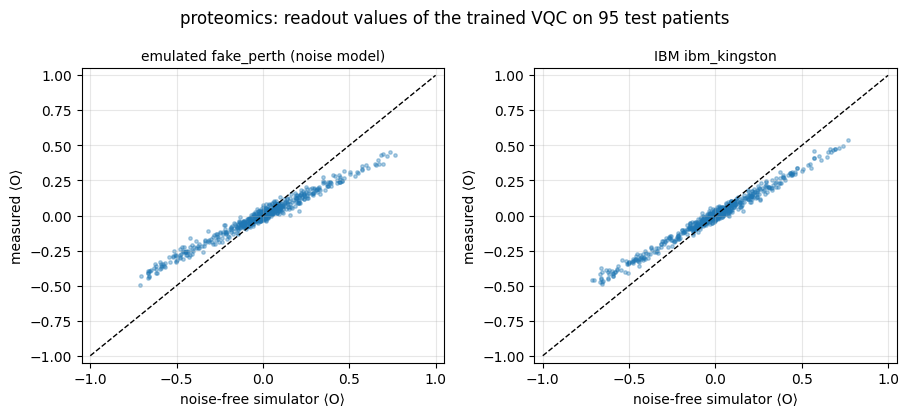

In [29]:
# %% ---------------- CELL E4 — F1 on hardware vs the noise-free simulator ----------------
sel = [MEM[m] for m in HW_MEMBERS]; Z_SIM = [z0[m] for m in HW_MEMBERS]
P_SIM = ensemble_probs(sel, Z_SIM); pred_sim = P_SIM.argmax(1)
rows = []


def add_row(label, pred, z=None, models=None):
    lo, hi = ci(y_te, pred); r = {"setting": label, "models": len(HW_MEMBERS) if models is None else models, "test_macro_f1": mf1(y_te, pred), "ci_low": lo, "ci_high": hi}
    if z is not None:
        d, dlo, dhi, pv = paired(y_te, pred, pred_sim)
        r.update({"minus_noise_free": d, "diff_ci_low": dlo, "diff_ci_high": dhi, "p": pv,
                  "same_prediction_as_noise_free": float((pred == pred_sim).mean()),
                  "readout_mean_abs_error": float(np.mean([np.abs(z[m] - z0[m]).mean() for m in HW_MEMBERS])),
                  "readout_correlation": float(np.corrcoef(np.concatenate([z[m].ravel() for m in HW_MEMBERS]),
                                                           np.concatenate([z0[m].ravel() for m in HW_MEMBERS]))[0, 1])})
    rows.append(r)


add_row("noise-free simulator (same models)", pred_sim)
for label, z in HW_RUNS.items():
    add_row(label, ensemble_probs(sel, [z[m] for m in HW_MEMBERS]).argmax(1), z)
if len(HW_MEMBERS) < len(MEM):
    add_row(f"reference: full {len(MEM)}-model ensemble, simulator", VQC_TEST_RERUN.argmax(1), models=len(MEM))
try:
    lr = C2[C2.model.str.startswith("LR (same")].iloc[0]
    rows.append({"setting": "reference: LR on the same features (Part C)", "test_macro_f1": lr.test_macro_f1, "ci_low": lr.ci_low, "ci_high": lr.ci_high})
except Exception:
    pass
E4 = pd.DataFrame(rows); E4.to_csv(os.path.join(E_DIR, "E4_hardware_f1.csv"), index=False); display(E4.round(3))

if HW_RUNS:
    fig, axs = plt.subplots(1, len(HW_RUNS), figsize=(4.6 * len(HW_RUNS), 4.2), squeeze=False)
    for ax, (label, z) in zip(axs[0], HW_RUNS.items()):
        a = np.concatenate([z0[m].ravel() for m in HW_MEMBERS]); b = np.concatenate([z[m].ravel() for m in HW_MEMBERS])
        ax.scatter(a, b, s=6, alpha=.35); ax.plot([-1, 1], [-1, 1], "k--", lw=1)
        ax.set_xlabel("noise-free simulator ⟨O⟩"); ax.set_ylabel("measured ⟨O⟩"); ax.set_title(label, fontsize=10)
        ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05); ax.grid(alpha=.3)
    fig.suptitle(f"{MODALITY}: readout values of the trained VQC on {B_TE} test patients"); fig.tight_layout()
    fig.savefig(os.path.join(E_DIR, "figE_hardware_vs_simulator.png"), dpi=300); plt.show()

In [30]:
# %% ---------------- CELL E5 — what to write in the paper ----------------
r0 = E4.iloc[0]
print(f"• {MODALITY}: trained VQC ({n_q} qubits; {RES_E.two_qubit_gates.iloc[0]} native two-qubit gates and depth "
      f"{RES_E.depth.iloc[0]} after compilation for {BK}) evaluated on the {B_TE} held-out test patients, "
      f"{len(HW_MEMBERS)} model(s), {SHOTS} shots per patient.")
print(f"• Noise-free simulator: test macro-F1 {r0.test_macro_f1:.3f} (95% CI {r0.ci_low:.3f}–{r0.ci_high:.3f}).")
for r in E4.iloc[1:].itertuples():
    if isinstance(getattr(r, "minus_noise_free", None), float) and not np.isnan(r.minus_noise_free):
        print(f"• {r.setting}: test macro-F1 {r.test_macro_f1:.3f} (95% CI {r.ci_low:.3f}–{r.ci_high:.3f}); difference from "
              f"noise-free {r.minus_noise_free:+.3f} (95% CI {r.diff_ci_low:+.3f} to {r.diff_ci_high:+.3f}, p = {r.p:.3f}); "
              f"same predicted class for {100 * r.same_prediction_as_noise_free:.1f}% of patients; readout correlation "
              f"{r.readout_correlation:.3f}.")
if os.path.exists(JOB_FILE):
    m = json.load(open(JOB_FILE))
    print(f"• Methods detail: IBM job {m.get('job_id')} on {m.get('backend')} ({m.get('finished', m.get('submitted'))}); "
          f"Estimator resilience level {m.get('resilience_level')}, dynamical decoupling {m.get('dynamical_decoupling')}, "
          f"gate twirling {m.get('gate_twirling')}; QPU time {m.get('qpu_seconds')} s. Calibration of the qubits used: E2_calibration.csv.")
print("• Training was done on a noise-free simulator; only inference was run on the quantum device.")
print("\nSaved in", E_DIR, ":", sorted(os.listdir(E_DIR)))


• proteomics: trained VQC (6 qubits; 56 native two-qubit gates and depth 185 after compilation for ibm_kingston) evaluated on the 95 held-out test patients, 1 model(s), 2048 shots per patient.
• Noise-free simulator: test macro-F1 0.521 (95% CI 0.414–0.617).
• emulated fake_perth (noise model): test macro-F1 0.505 (95% CI 0.399–0.595); difference from noise-free -0.015 (95% CI -0.085 to +0.053, p = 0.709); same predicted class for 82.1% of patients; readout correlation 0.987.
• IBM ibm_kingston: test macro-F1 0.480 (95% CI 0.373–0.572); difference from noise-free -0.039 (95% CI -0.103 to +0.021, p = 0.216); same predicted class for 85.3% of patients; readout correlation 0.991.
• Methods detail: IBM job dbng68dt7fqc73ajjvq0 on None (2026-11-11 16:07:51); Estimator resilience level None, dynamical decoupling None, gate twirling None; QPU time 69.0 s. Calibration of the qubits used: E2_calibration.csv.
• Training was done on a noise-free simulator; only inference was run on the quantum de

,modality,device,test_patients,flipped,flipped_pct,median_margin_flipped,median_margin_unflipped,p_flipped_have_smaller_margin,flips_in_lowest_margin_quarter_pct,max_margin_of_a_flip,correct_to_wrong,wrong_to_correct,wrong_to_wrong
0,proteomics,ibm_kingston,95,14,14.737,0.045,0.299,0.0,71.429,0.126,7,4,3


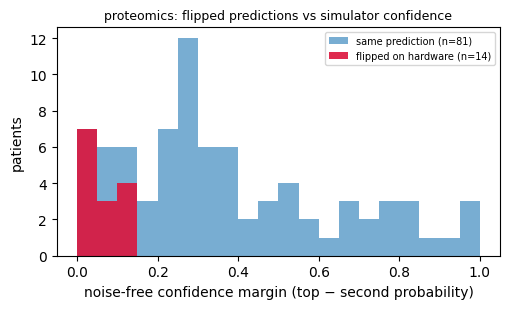

• proteomics: 14 of 95 test patients (14.7%) changed prediction on hardware; their median noise-free margin was 0.045 vs 0.299 for the others (one-sided Mann–Whitney p = 7.4e-07), the largest margin of a flipped patient was 0.126; flips: 7 correct→wrong, 4 wrong→correct, 3 wrong→wrong.
Saved: /kaggle/working/hw_probs_proteomics.csv and E6_flip_analysis.csv, E6_flipped_patients.csv, figE6_flip_margin.png in /kaggle/working/partE_proteomics


In [31]:
# %% ---------------- CELL E6 — export the hardware probabilities for fusion + flipped-prediction analysis ----------------
# Needs the IBM result in this session: E0 with SUBMIT_TO_IBM = False and RETRIEVE_JOB_ID = "<this modality's job ID>",
# then E0-E4 (or Run All). Uses no QPU time. Writes hw_probs_<modality>.csv (for the fusion notebook) and
# E6_flip_analysis.csv / E6_flipped_patients.csv (which patients changed prediction on hardware, and how sure the model was).
from scipy.stats import mannwhitneyu
hw_key = next((k for k in HW_RUNS if k.startswith("IBM ")), None)
assert hw_key is not None, "No IBM hardware result in this session: set RETRIEVE_JOB_ID in E0 (SUBMIT_TO_IBM = False) and run E0-E4 first."
P_HW = ensemble_probs(sel, [HW_RUNS[hw_key][m] for m in HW_MEMBERS])      # the same model(s) on IBM hardware
P_NF = ensemble_probs(sel, Z_SIM)                                         # the same model(s), noise-free simulator
assert len(te_ids) == len(P_HW) == len(y_te), "test-patient order mismatch"
parts = []
for kind, P in [("hardware", P_HW), ("noise_free_same_model", P_NF)]:
    d = pd.DataFrame(P, columns=CLASSES); d.insert(0, "kind", kind); d.insert(0, "patient", [str(p) for p in te_ids])
    parts.append(d)
hw_file = os.path.join(OUTPUT_DIR, f"hw_probs_{MODALITY}.csv")
pd.concat(parts, ignore_index=True).to_csv(hw_file, index=False)

# ---- flipped predictions vs the simulator's confidence margin (top probability minus second) ----
srt = np.sort(P_NF, 1); margin = srt[:, -1] - srt[:, -2]
pred_nf, pred_hw = P_NF.argmax(1), P_HW.argmax(1); flip = pred_hw != pred_nf
q1 = margin <= np.quantile(margin, 0.25)
p_mw = float(mannwhitneyu(margin[flip], margin[~flip], alternative="less").pvalue) if 0 < flip.sum() < len(flip) else np.nan
FLIP = pd.DataFrame([{
    "modality": MODALITY, "device": hw_key.replace("IBM ", ""), "test_patients": len(flip), "flipped": int(flip.sum()),
    "flipped_pct": 100 * flip.mean(),
    "median_margin_flipped": float(np.median(margin[flip])) if flip.any() else np.nan,
    "median_margin_unflipped": float(np.median(margin[~flip])),
    "p_flipped_have_smaller_margin": p_mw,
    "flips_in_lowest_margin_quarter_pct": 100 * (flip & q1).sum() / max(flip.sum(), 1),
    "max_margin_of_a_flip": float(margin[flip].max()) if flip.any() else np.nan,
    "correct_to_wrong": int((flip & (pred_nf == y_te)).sum()), "wrong_to_correct": int((flip & (pred_hw == y_te)).sum()),
    "wrong_to_wrong": int((flip & (pred_nf != y_te) & (pred_hw != y_te)).sum())}])
FLIP.to_csv(os.path.join(E_DIR, "E6_flip_analysis.csv"), index=False)
pd.DataFrame({"patient": [str(p) for p in te_ids], "true": [CLASSES[i] for i in y_te],
              "pred_noise_free": [CLASSES[i] for i in pred_nf], "pred_hardware": [CLASSES[i] for i in pred_hw],
              "margin_noise_free": margin, "flipped": flip}).to_csv(os.path.join(E_DIR, "E6_flipped_patients.csv"), index=False)
display(FLIP.round(3))

fig, ax = plt.subplots(figsize=(5.2, 3.2))
bins = np.linspace(0, 1, 21)
ax.hist(margin[~flip], bins=bins, alpha=.6, label=f"same prediction (n={int((~flip).sum())})")
ax.hist(margin[flip], bins=bins, alpha=.9, label=f"flipped on hardware (n={int(flip.sum())})", color="crimson")
ax.set_xlabel("noise-free confidence margin (top − second probability)"); ax.set_ylabel("patients"); ax.legend(fontsize=7)
ax.set_title(f"{MODALITY}: flipped predictions vs simulator confidence", fontsize=9); fig.tight_layout()
fig.savefig(os.path.join(E_DIR, "figE6_flip_margin.png"), dpi=200); plt.show()
r = FLIP.iloc[0]
print(f"• {MODALITY}: {r.flipped} of {r.test_patients} test patients ({r.flipped_pct:.1f}%) changed prediction on hardware"
      + (f"; their median noise-free margin was {r.median_margin_flipped:.3f} vs {r.median_margin_unflipped:.3f} for the others "
         f"(one-sided Mann–Whitney p = {r.p_flipped_have_smaller_margin:.3g}), the largest margin of a flipped patient was "
         f"{r.max_margin_of_a_flip:.3f}; flips: {r.correct_to_wrong} correct→wrong, {r.wrong_to_correct} wrong→correct, "
         f"{r.wrong_to_wrong} wrong→wrong." if r.flipped else "."))
print("Saved:", hw_file, "and E6_flip_analysis.csv, E6_flipped_patients.csv, figE6_flip_margin.png in", E_DIR)